In [1]:
from pathlib import Path
import numpy as np

import import_ipynb
import os
curdir = os.getcwd()
src_path = Path('../src/')
os.chdir(src_path)
from ML_Base import BaseModelWrapper, XANESVisualizer, XANESDataLoader, XANESPipeline
from Wrappers import CatBoostWrapper
os.chdir(curdir)

In [2]:
# Пути к сценарию 1A
paths_JanisLike = {
                    'train_x': Path('../processed_data/DataSets/JanisLike_Train_X.npz'),
                    'train_y': Path('../processed_data/DataSets/JanisLike_Train_y.npz'),
                    'test_x':  Path('../processed_data/DataSets/JanisLike_Test_X.npz'),
                    'test_y':  Path('../processed_data/DataSets/JanisLike_Test_y.npz'),
                  }

# Пути к сценарию 1B
paths_NotJanisLike = {
                    'train_x': Path('../processed_data/DataSets/NotJanisLike_Train_X.npz'),
                    'train_y': Path('../processed_data/DataSets/NotJanisLike_Train_y.npz'),
                    'test_x':  Path('../processed_data/DataSets/NotJanisLike_Test_X.npz'),
                    'test_y':  Path('../processed_data/DataSets/NotJanisLike_Test_y.npz'),
                  }

# Пути к сценарию 2A
paths_No_Strict = {
                    'train_x': Path('../processed_data/DataSets/No_Strict2A_Train_X.npz'),
                    'train_y': Path('../processed_data/DataSets/No_Strict2A_Train_y.npz'),
                    'test_x':  Path('../processed_data/DataSets/No_Strict2A_Test_X.npz'),
                    'test_y':  Path('../processed_data/DataSets/No_Strict2A_Test_y.npz'),
                  }


# Пути к сценарию 2B
paths_Lauvian = {
                    'train_x': Path('../processed_data/DataSets/Lauvian2B_Train_X.npz'),
                    'train_y': Path('../processed_data/DataSets/Lauvian2B_Train_y.npz'),
                    'test_x':  Path('../processed_data/DataSets/Lauvian2B_Test_X.npz'),
                    'test_y':  Path('../processed_data/DataSets/Lauvian2B_Test_y.npz'),
                }

In [3]:
# Используем стандартизацию данных или нет.
# Для древесных моделей не нужна.
STAND = False
E_GRID = np.arange(-10,60.1,0.5) # Сетка энергий для спектра

In [4]:
# Gemini
catboost_params = {
    # --- Основные параметры ---
    'iterations': 2000,          
    'learning_rate': 0.03,       
    'depth': 6,                  
    'loss_function': 'RMSE',
    
    # --- Регуляризация (Борьба с переобучением) ---
    'l2_leaf_reg': 3.0,          # L2-регуляризация (чем выше, тем консервативнее модель)
    'random_strength': 1.0,      # Добавляет случайность при выборе сплитов
    'bagging_temperature': 0.8,  # Интенсивность байесовского бутстрапа (0 - выкл, 1 - макс)
    
    # --- Специфика данных (Спектры) ---
    'bootstrap_type': 'Bayesian', 
    'leaf_estimation_method': 'Newton', # Обычно точнее для регрессии
    'feature_border_type': 'UniformAndQuantiles', # Важно для гладких спектров
    
    # --- Технические параметры ---
    'early_stopping_rounds': 100,
    'verbose': False,
    'allow_writing_files': False,
    'random_seed': 42
}

### Cценарий1A (JanisLike)


🚀 Моделирование CN1...


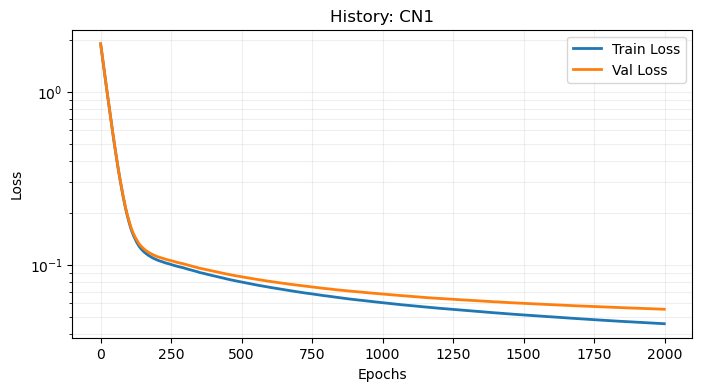

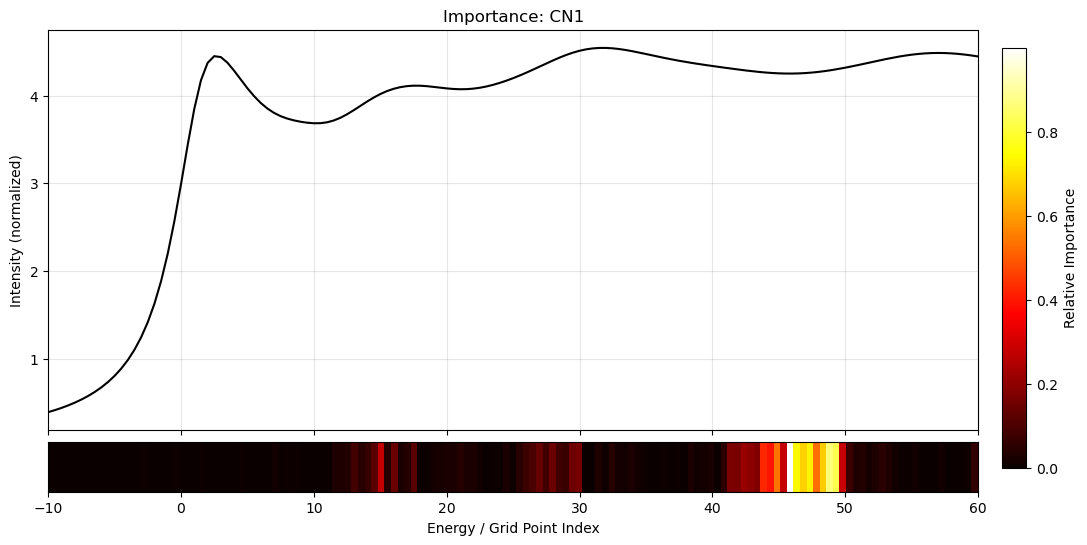

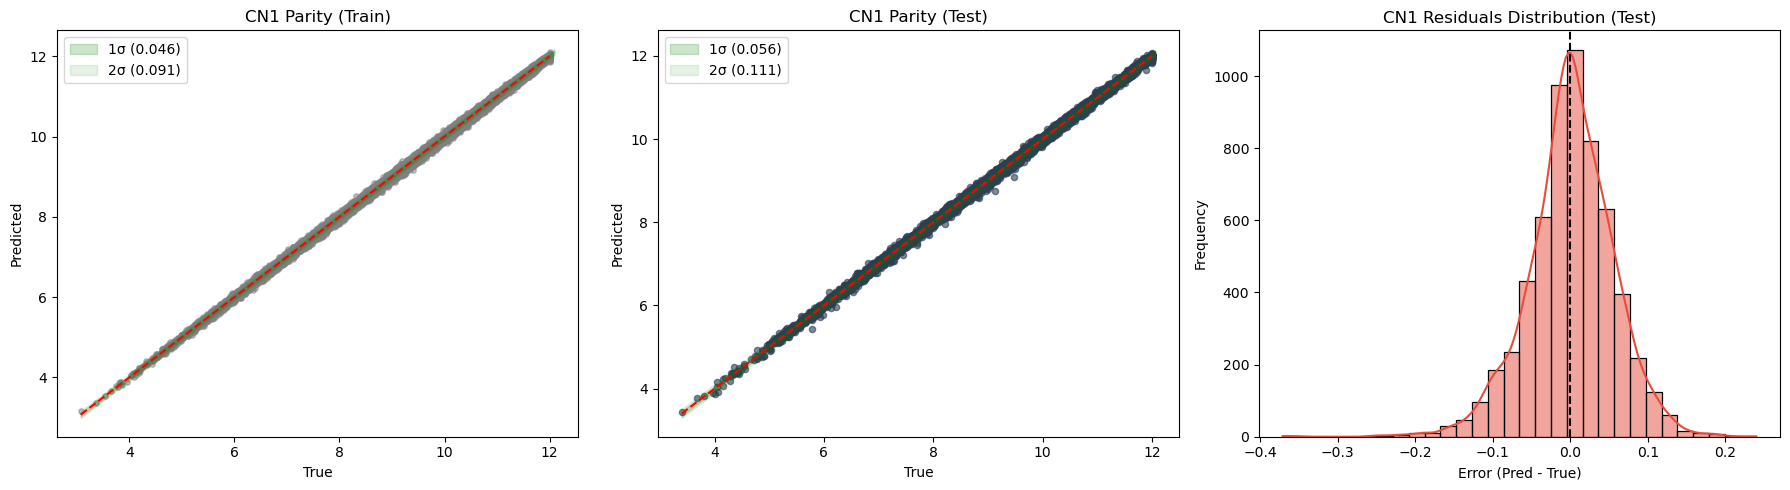


🚀 Моделирование CN2...


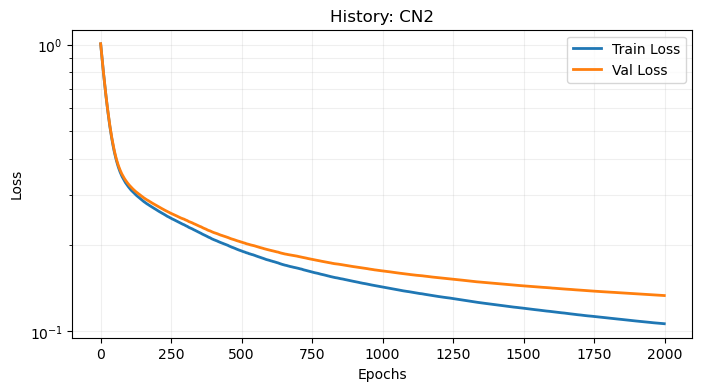

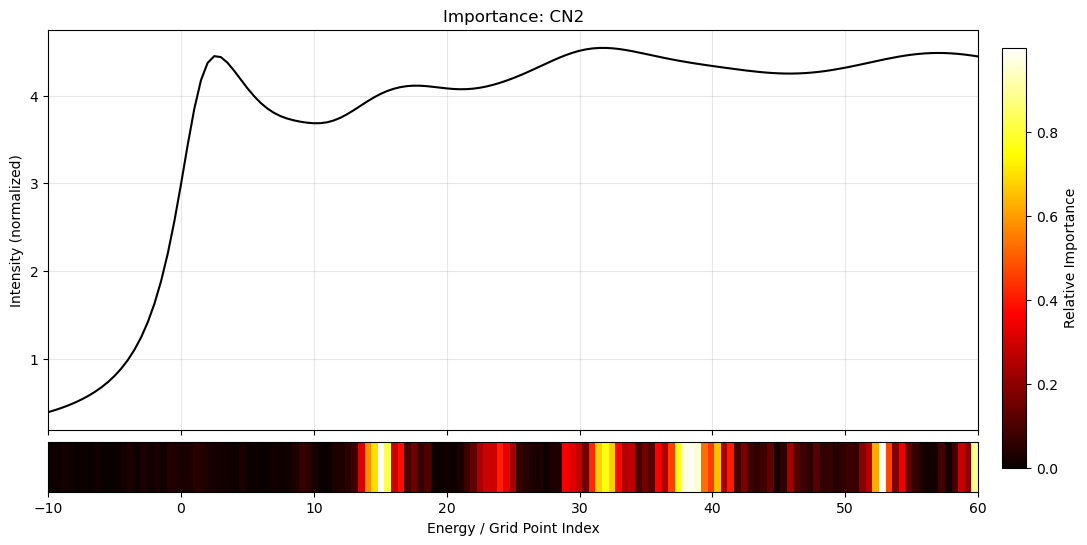

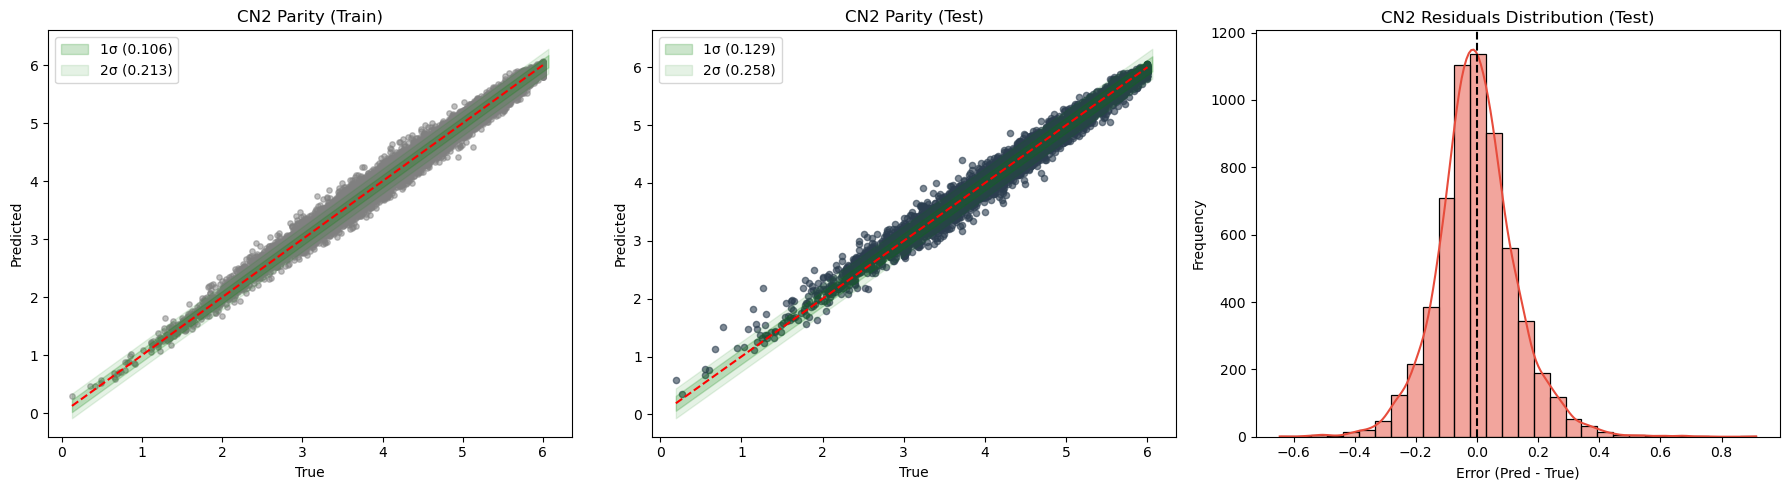


🚀 Моделирование CN3...


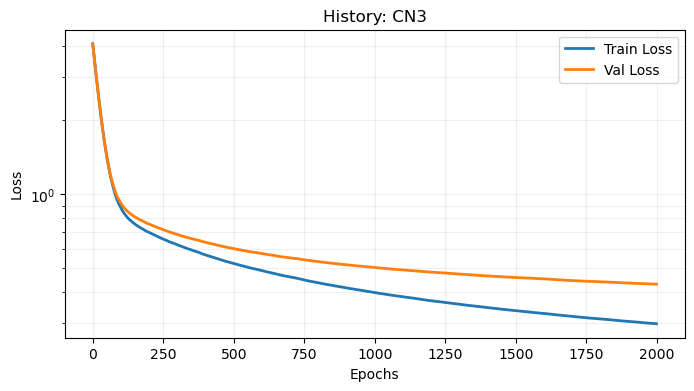

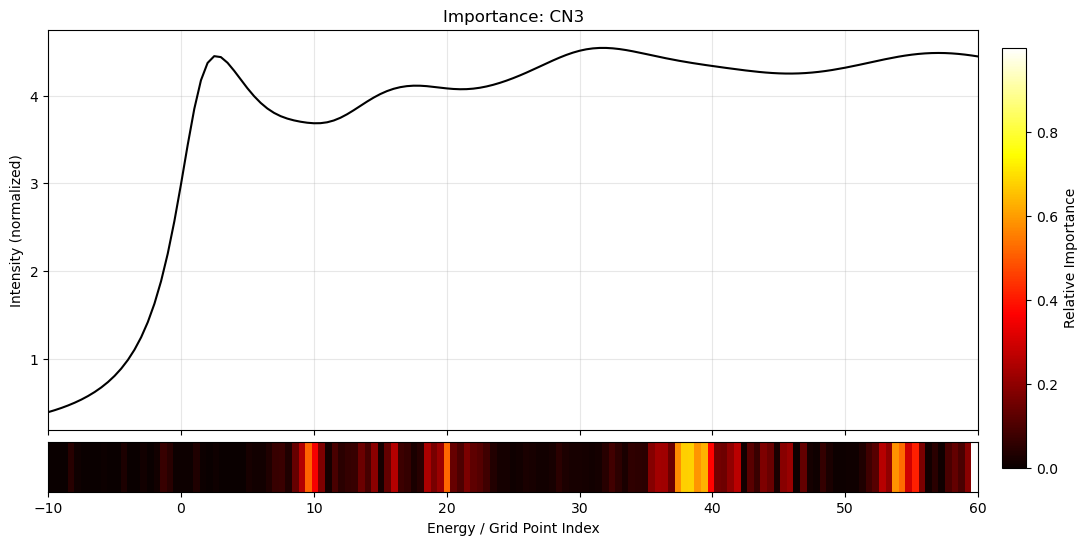

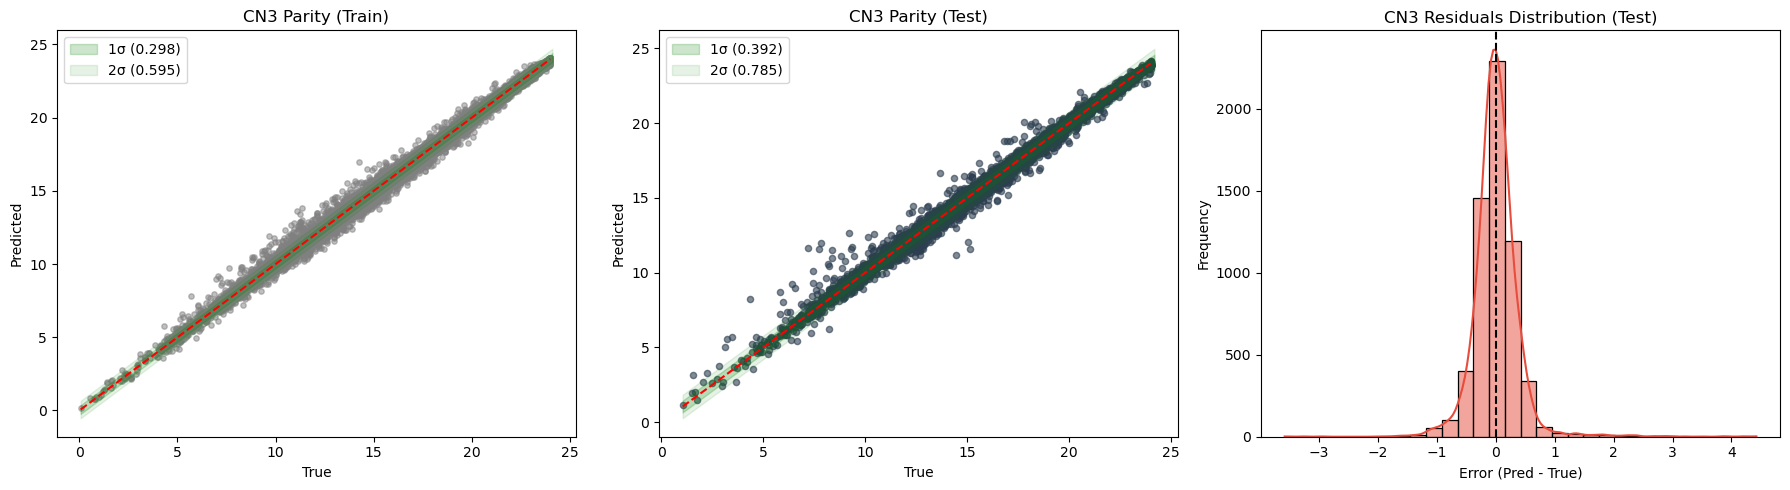


🚀 Моделирование CN4...


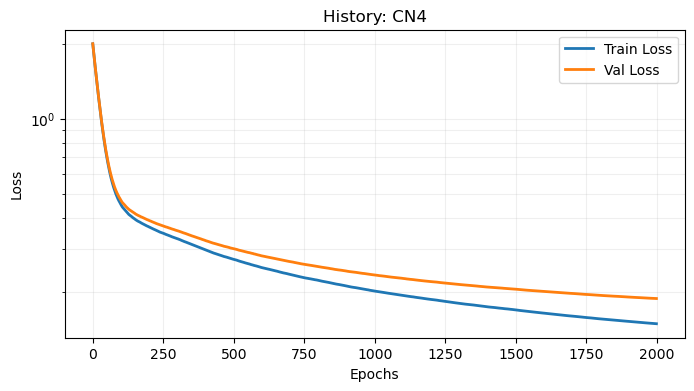

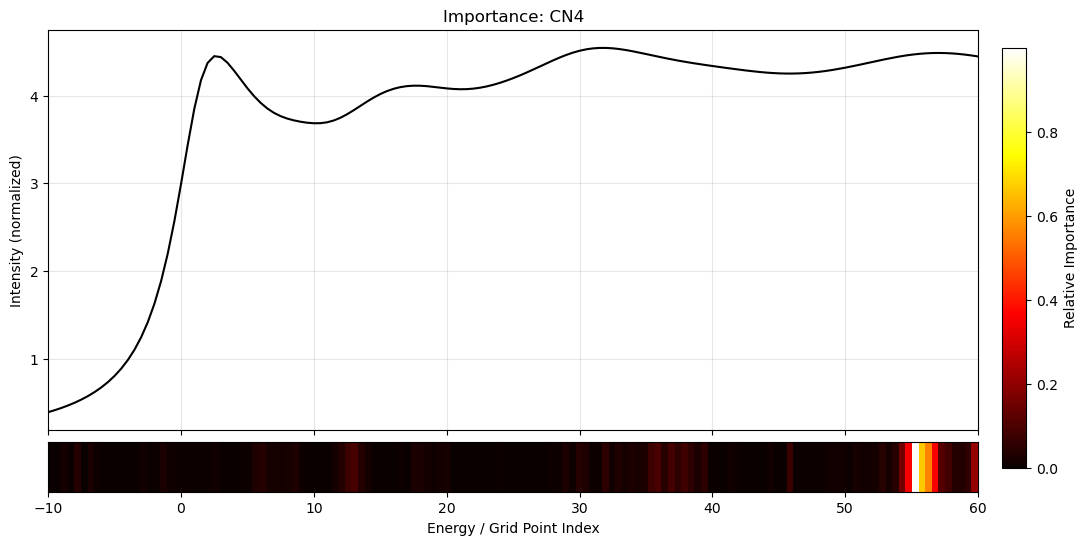

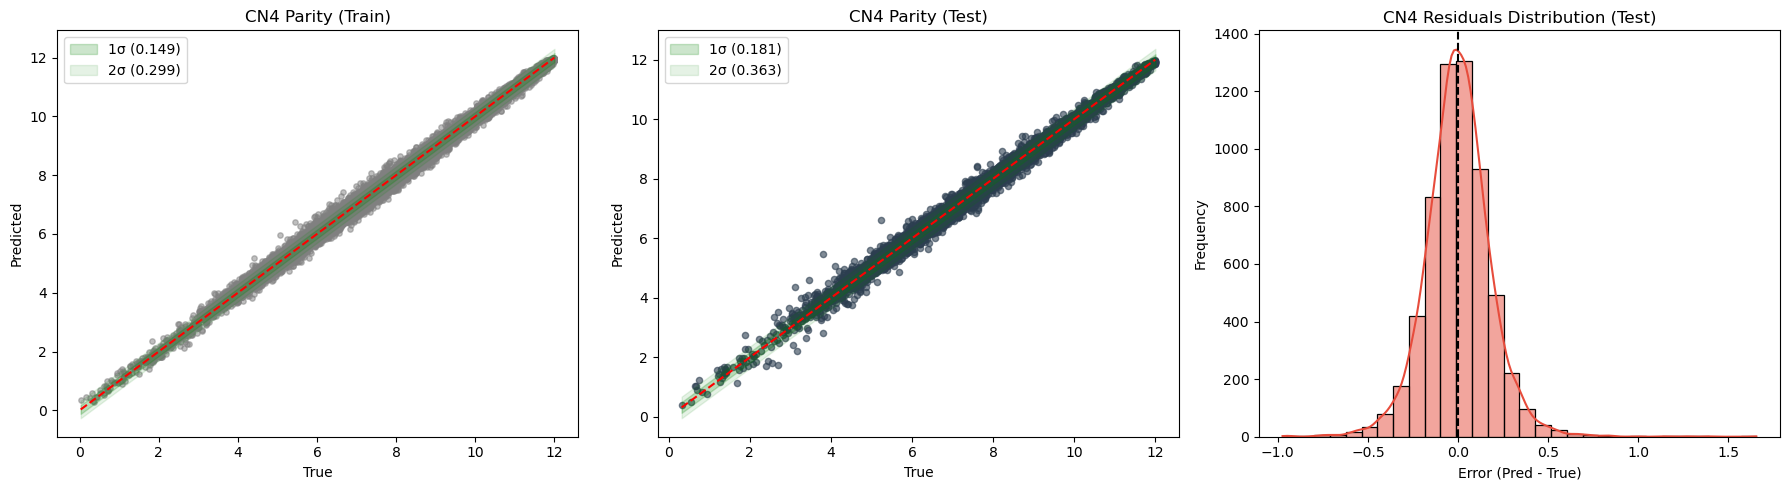


🚀 Моделирование CN5...


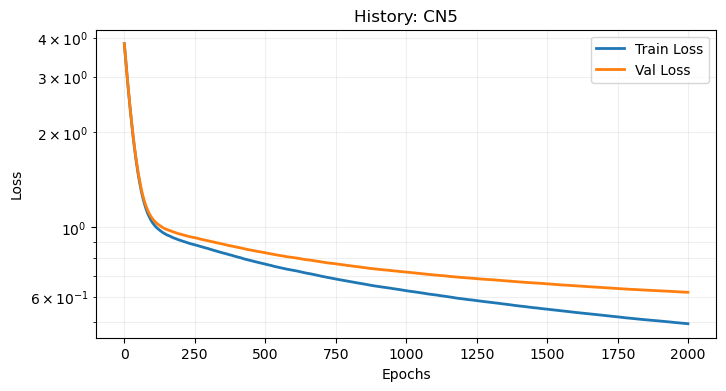

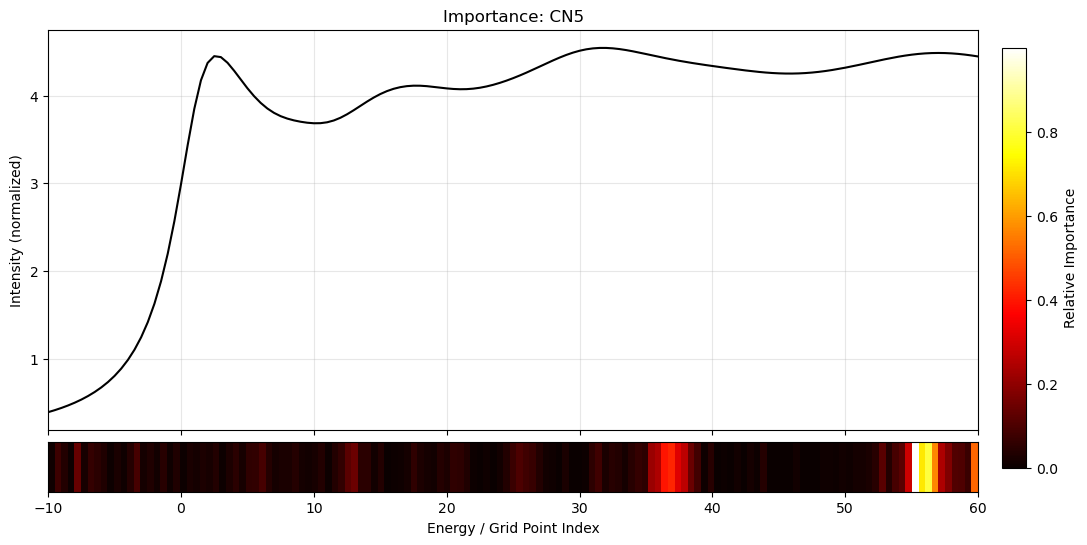

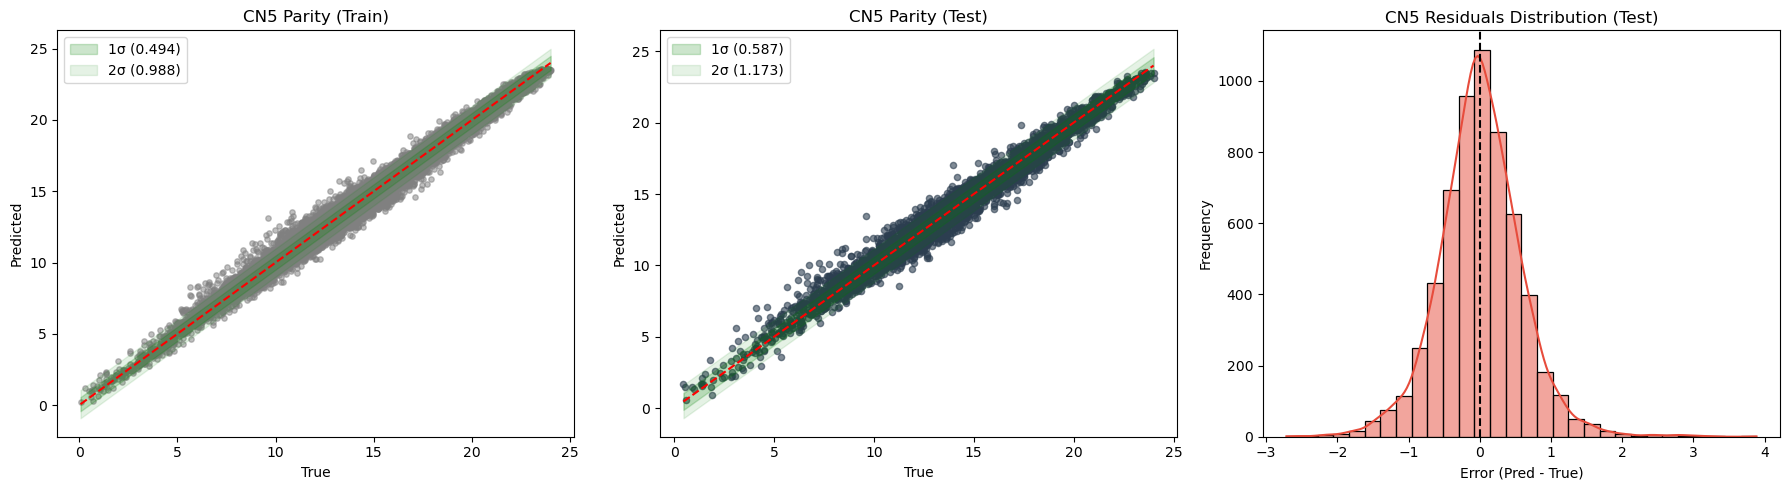


🚀 Моделирование CN6...


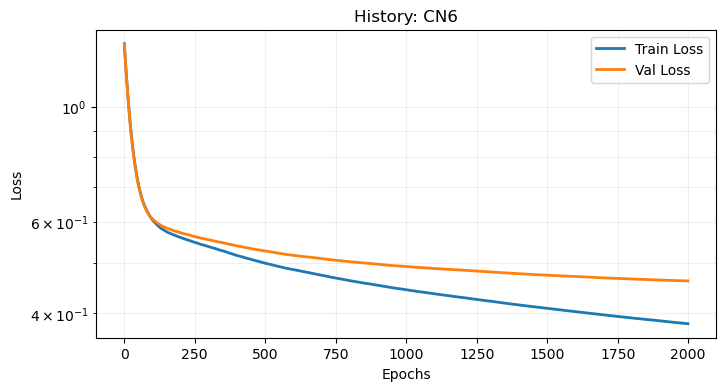

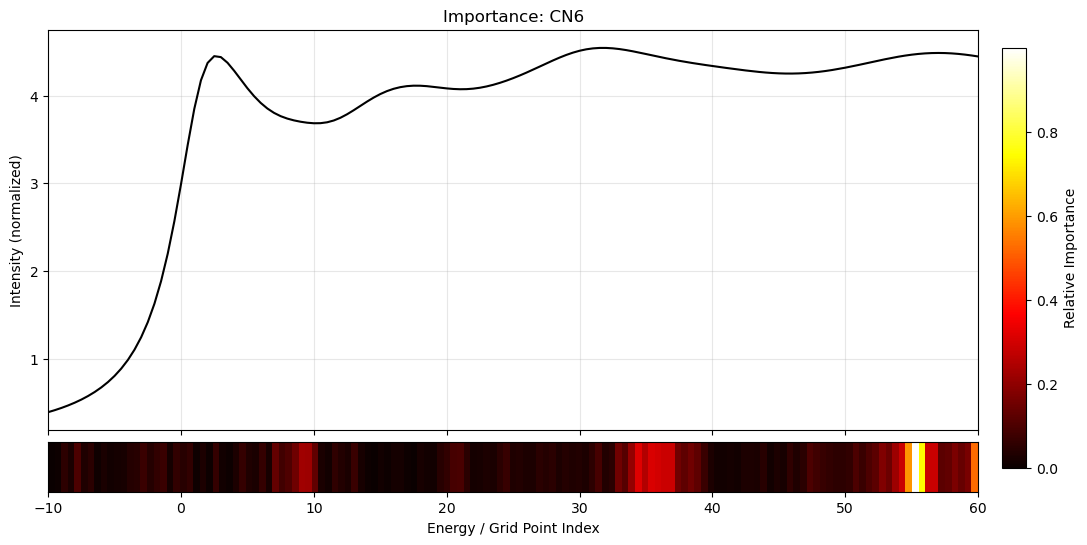

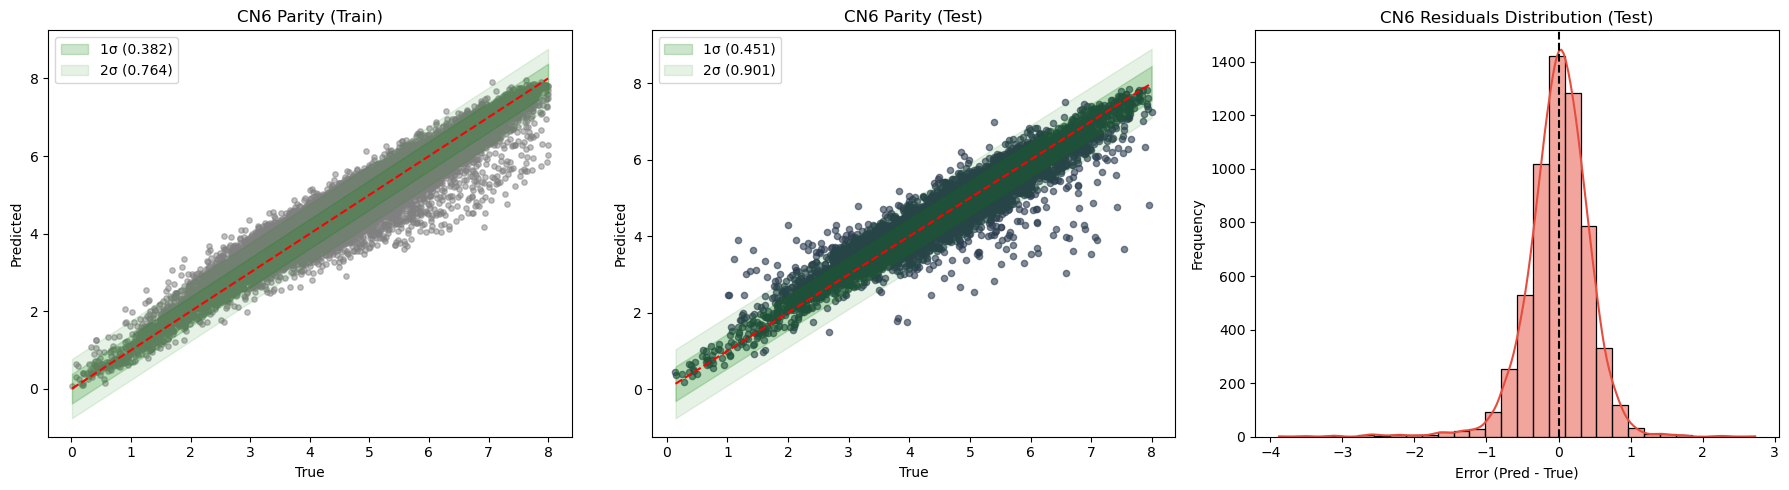


🚀 Моделирование CN7...


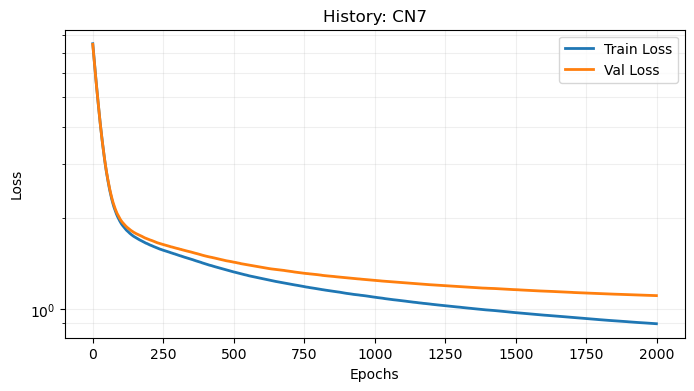

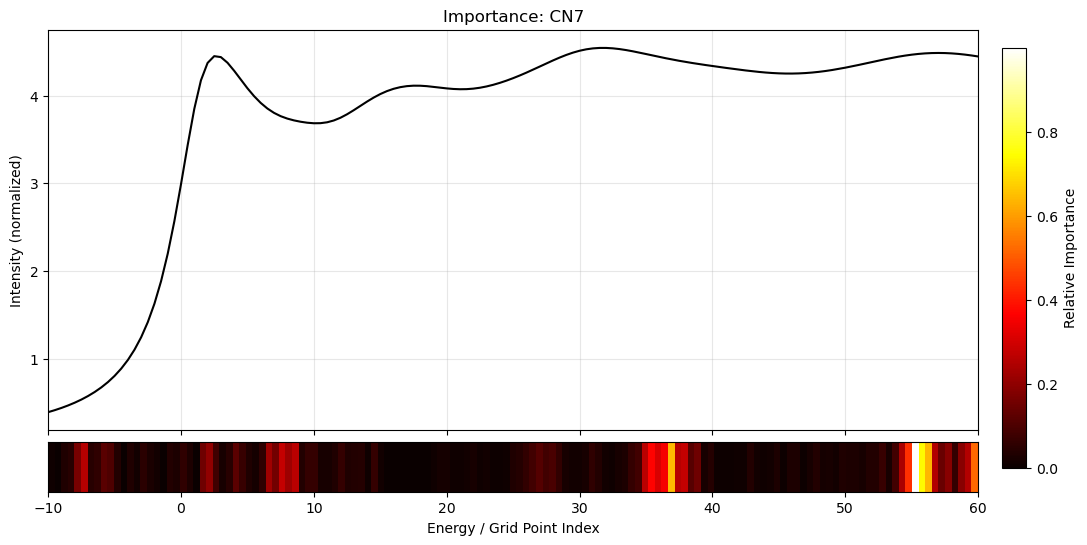

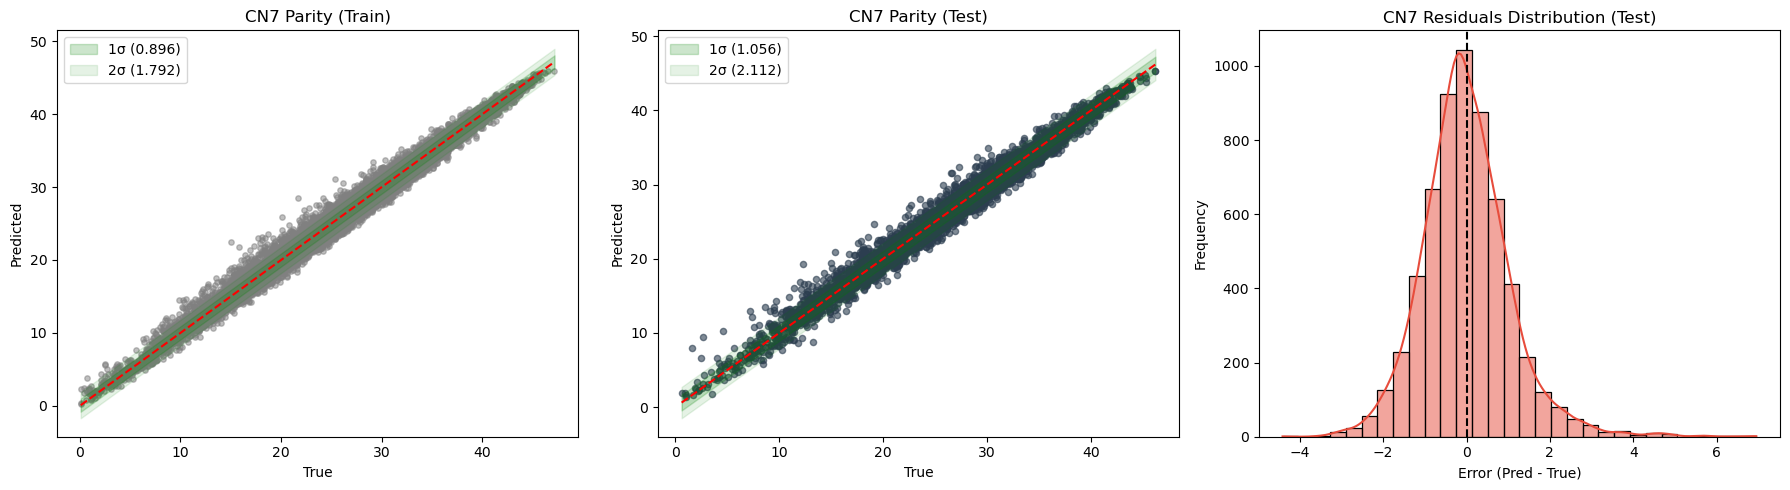


📊 ИТОГОВЫЙ ОТЧЕТ
           R2                  MAE              
Split    test  train    val   test  train    val
Target                                          
CN1    0.9992 0.9994 0.9992 0.0419 0.0352 0.0418
CN2    0.9845 0.9893 0.9833 0.0964 0.0810 0.1003
CN3    0.9915 0.9950 0.9894 0.2544 0.2149 0.2685
CN4    0.9924 0.9948 0.9916 0.1346 0.1147 0.1409
CN5    0.9780 0.9841 0.9749 0.4386 0.3767 0.4565
CN6    0.8887 0.9202 0.8824 0.3219 0.2848 0.3326
CN7    0.9811 0.9864 0.9790 0.7867 0.6791 0.8012
CPU times: total: 1h 51min 22s
Wall time: 8min 20s


In [5]:
%%time

save_root = Path('../processed_data/Results/JanisLike/CatBoost/')  
loader = XANESDataLoader(standardize=STAND)
viz = XANESVisualizer()
cbr = CatBoostWrapper(params=catboost_params)
pipeline_cbr = XANESPipeline(loader=loader, visualizer=viz, wrapper_instance=cbr, e_grid=E_GRID)
pipeline_cbr.run(paths=paths_JanisLike, save_root=save_root)

### Cценарий1B (NotJanisLike)


🚀 Моделирование CN1...


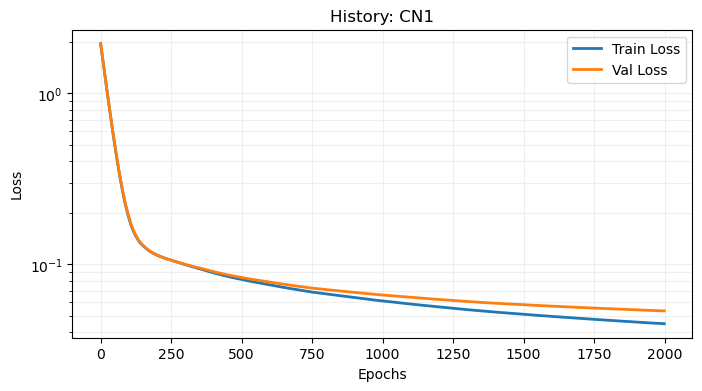

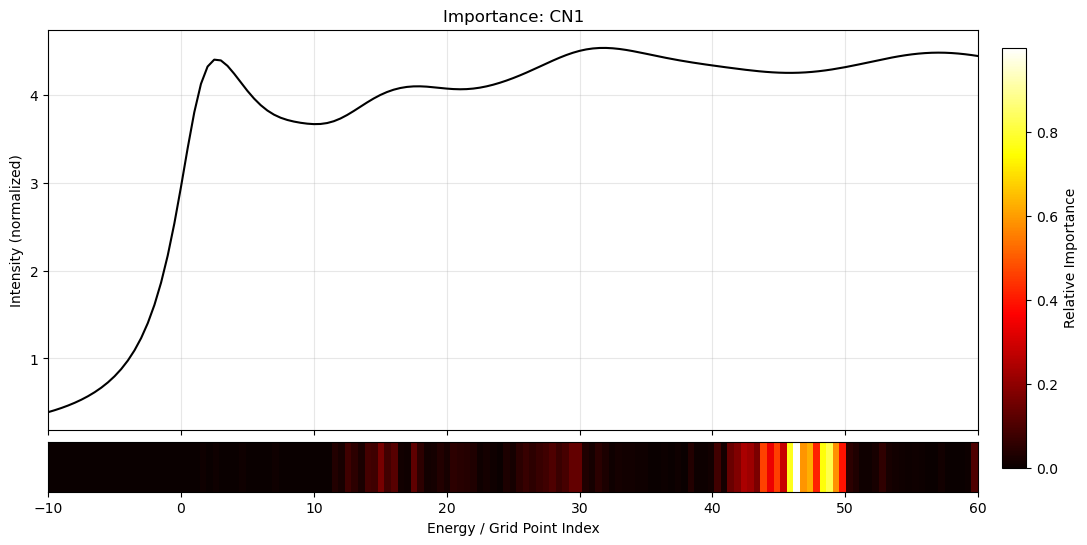

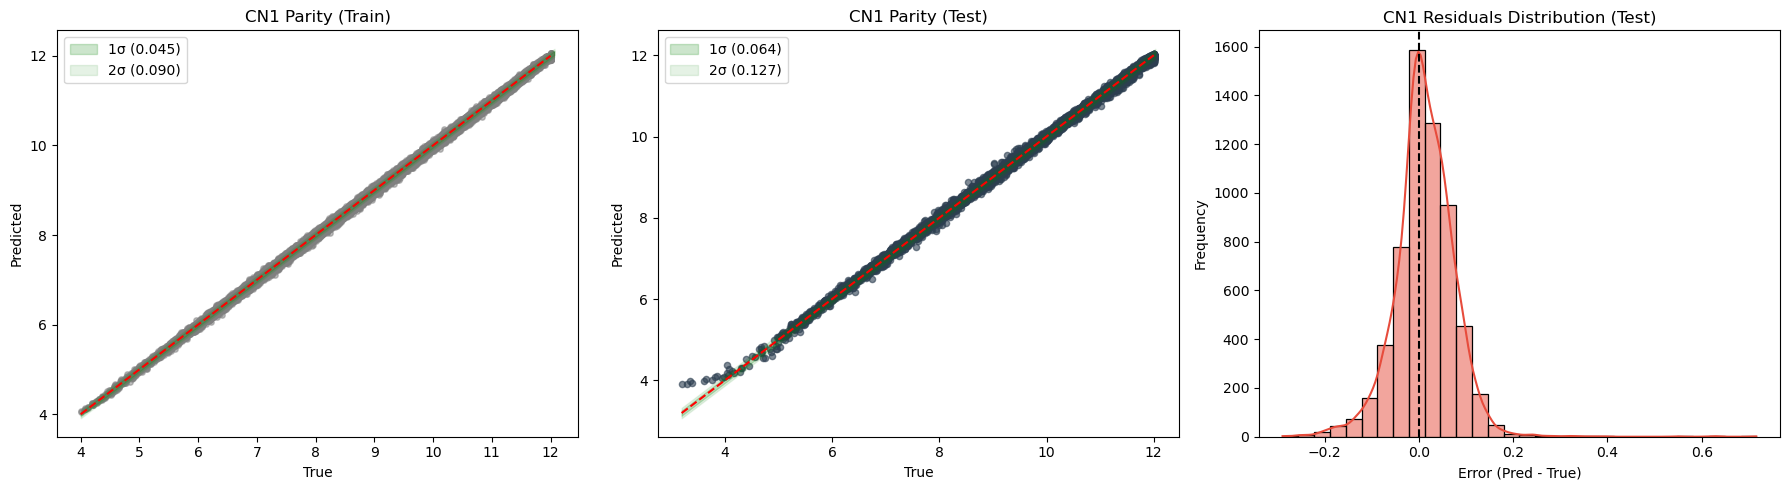


🚀 Моделирование CN2...


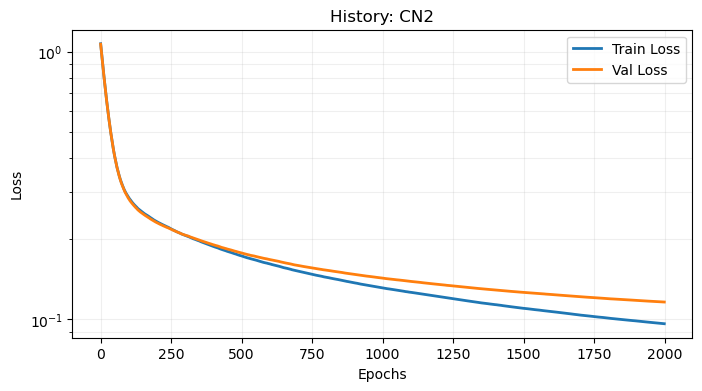

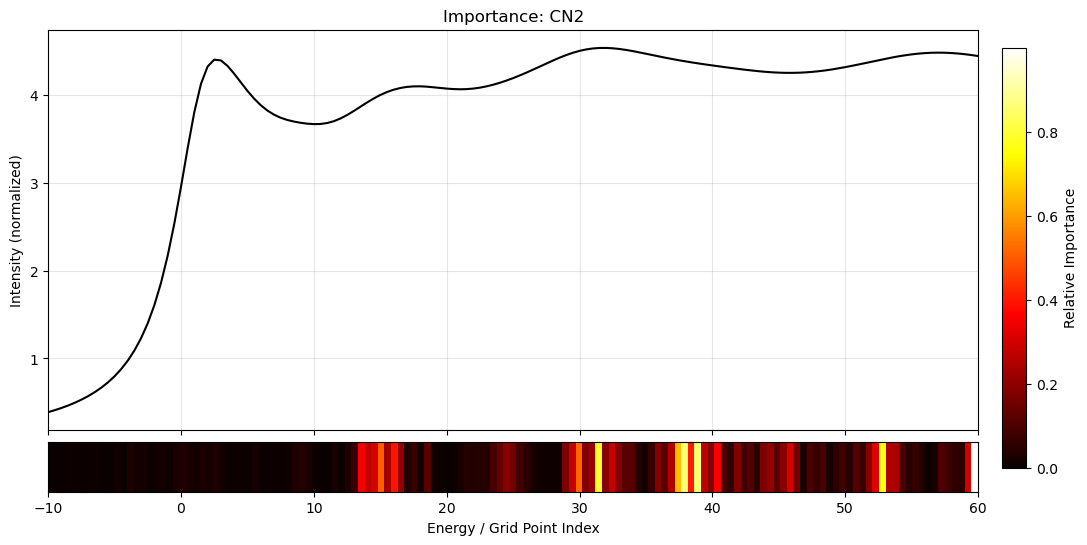

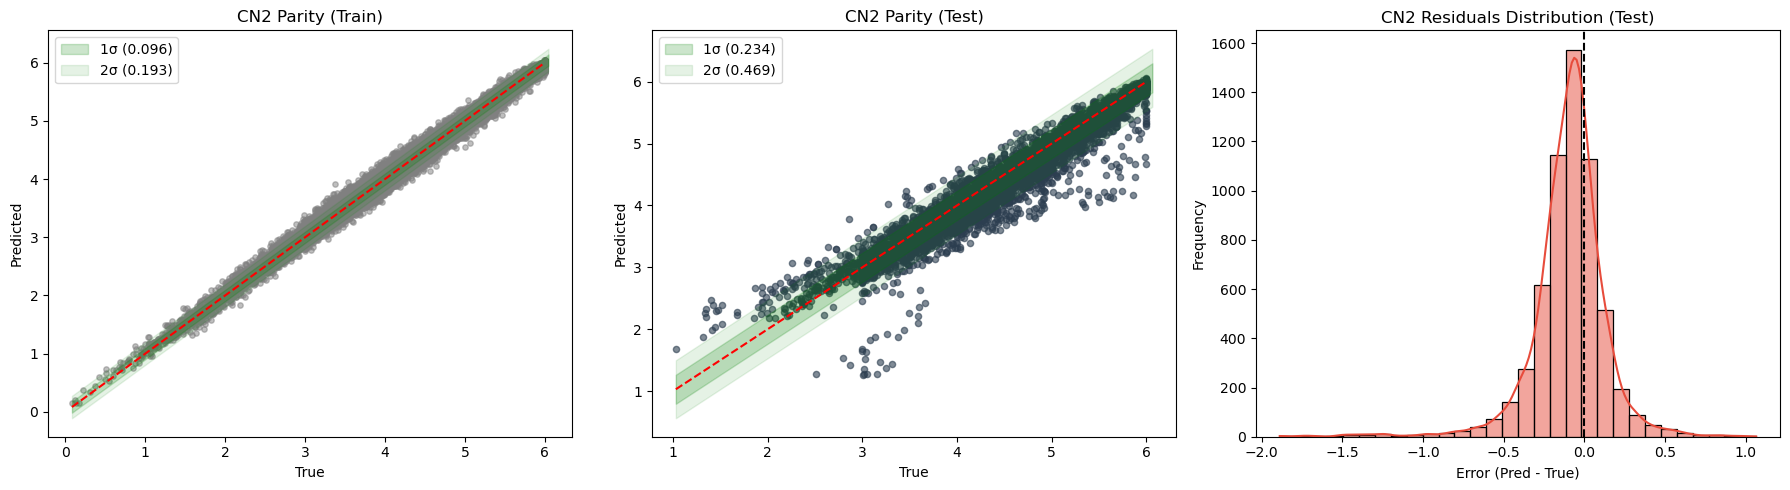


🚀 Моделирование CN3...


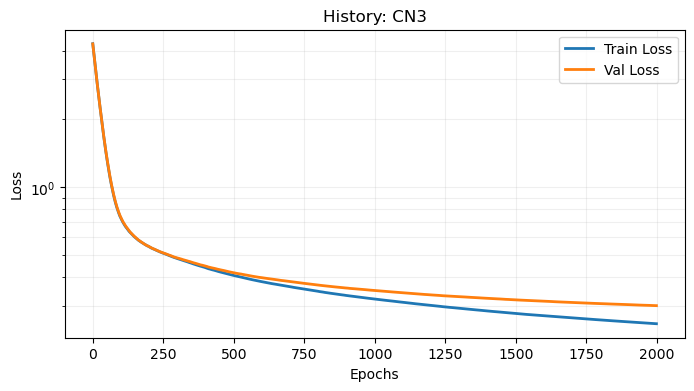

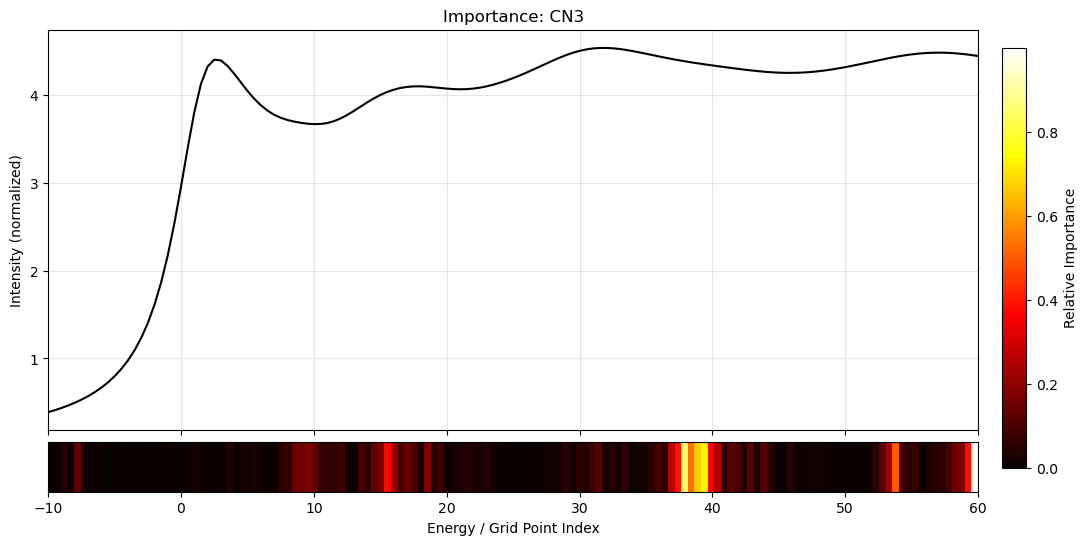

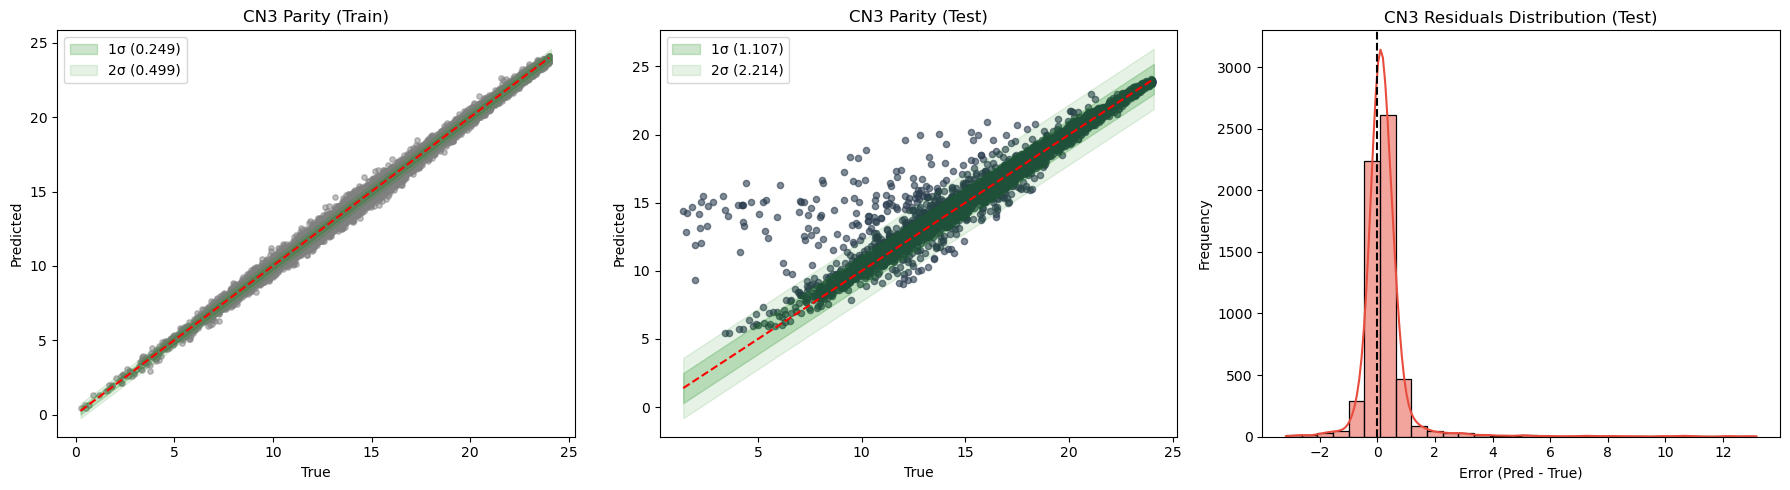


🚀 Моделирование CN4...


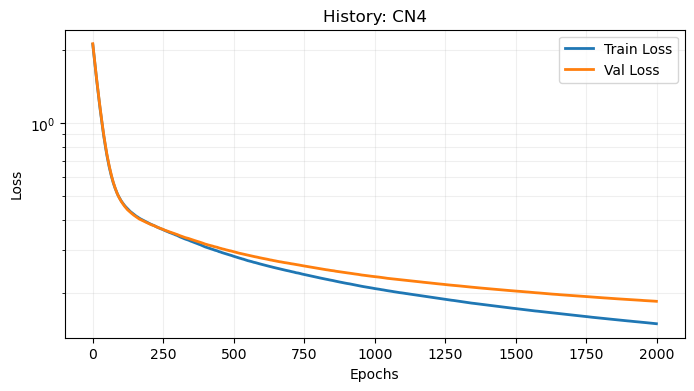

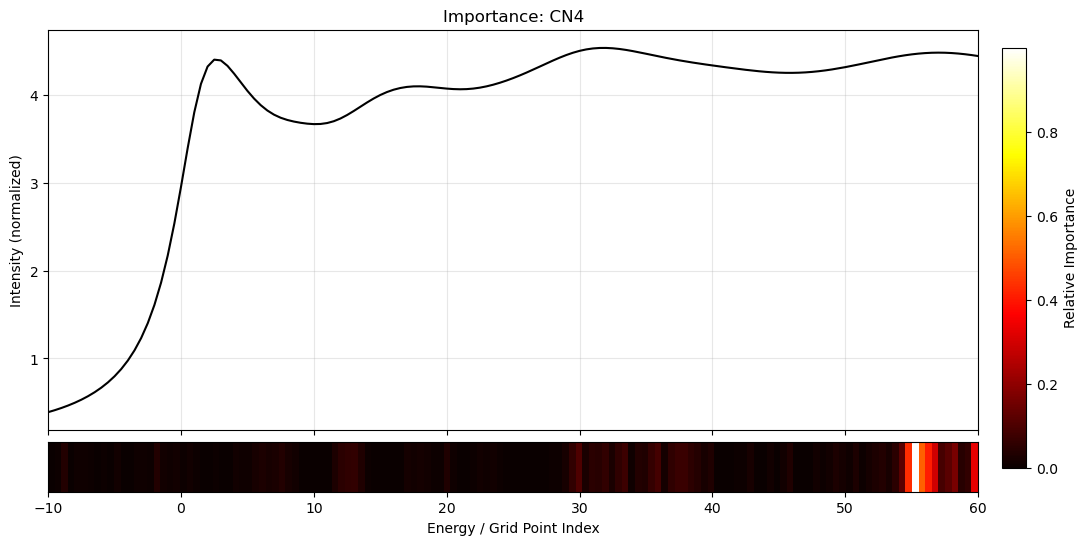

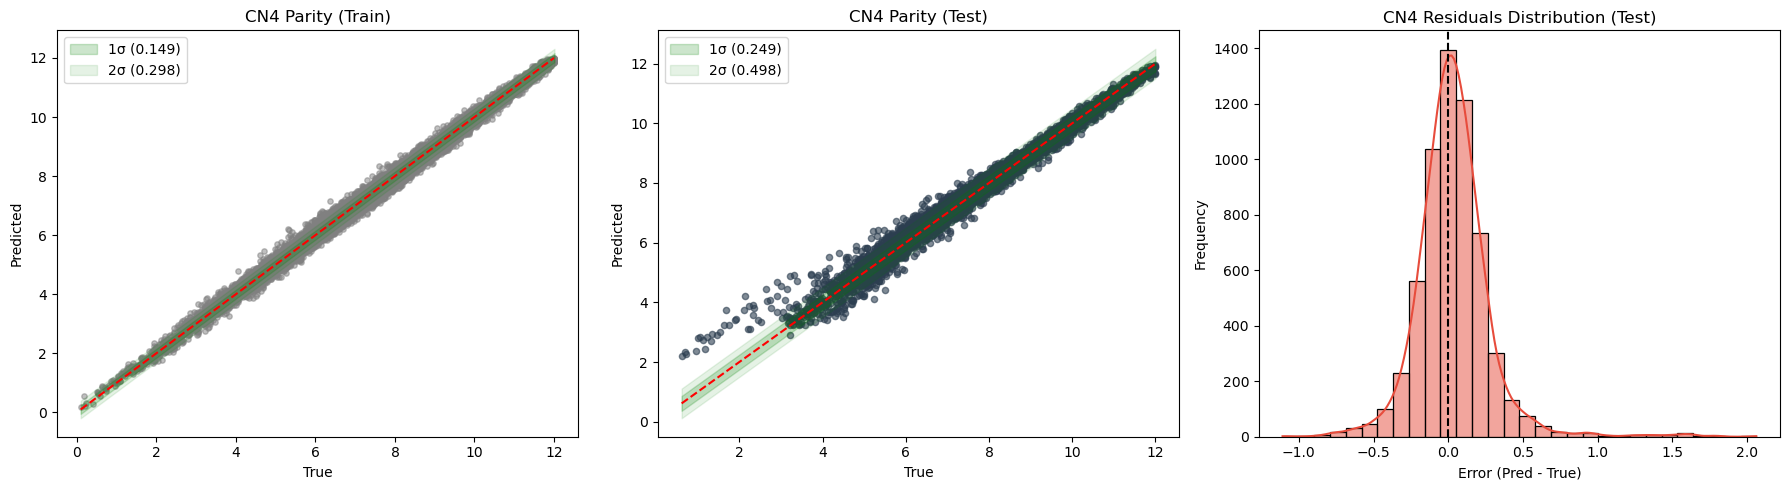


🚀 Моделирование CN5...


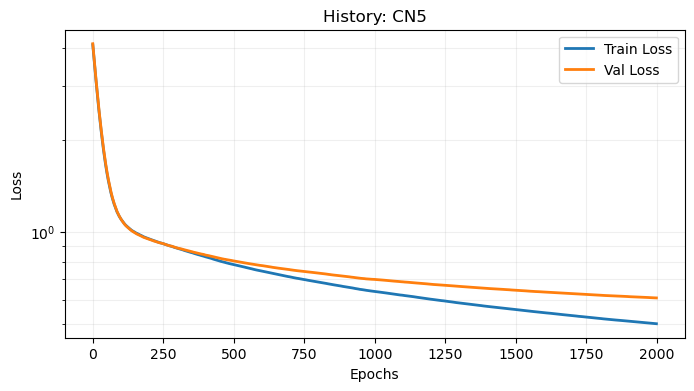

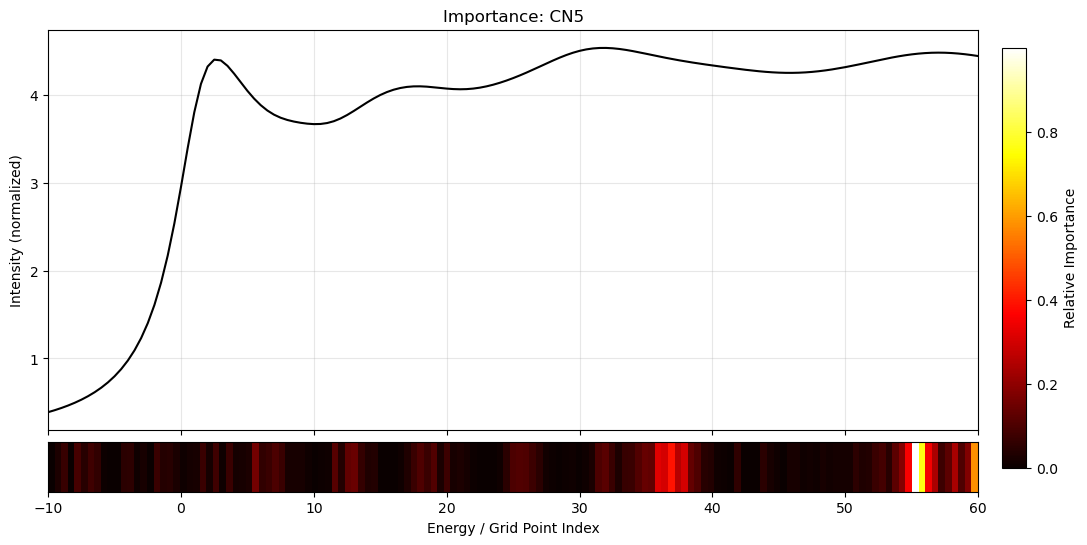

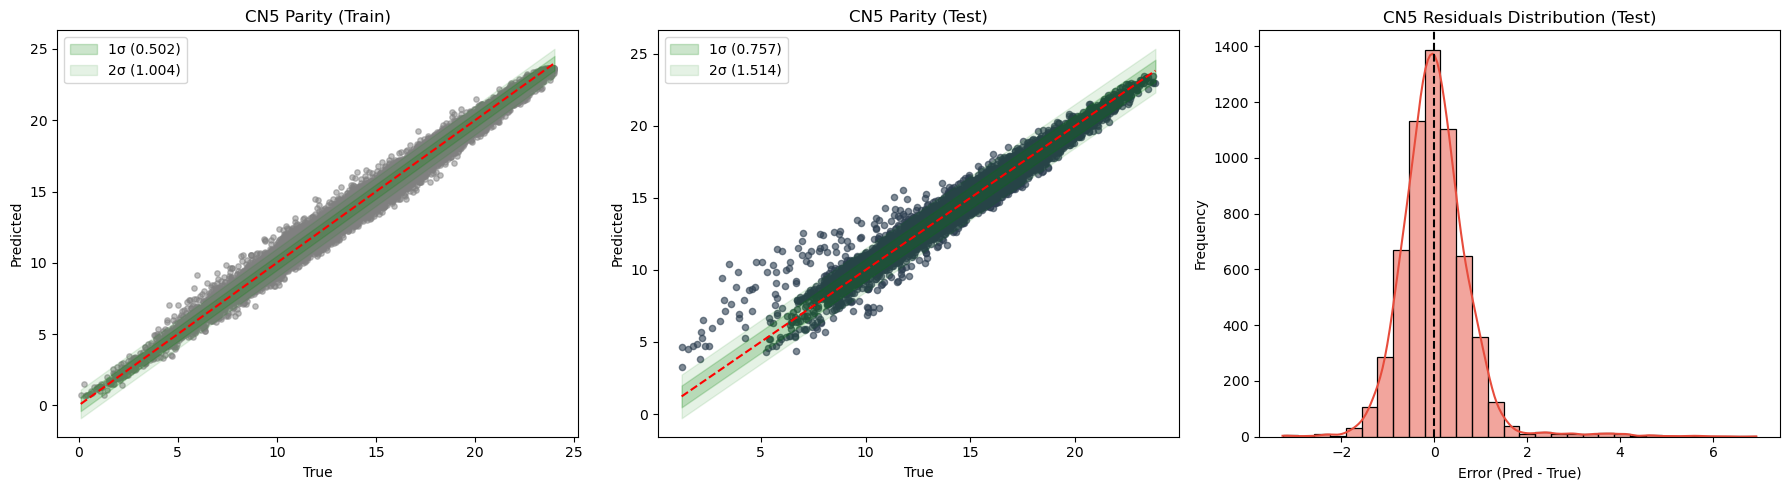


🚀 Моделирование CN6...


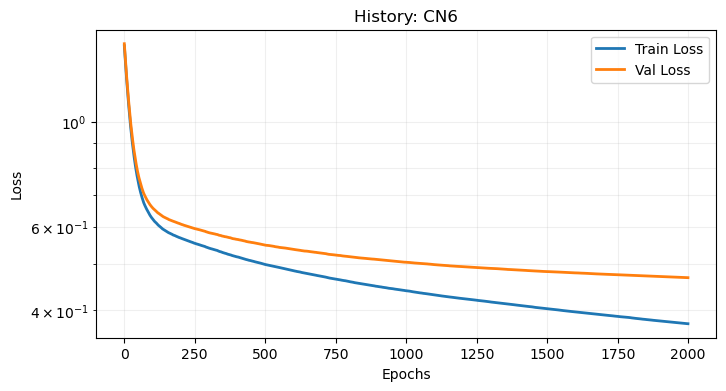

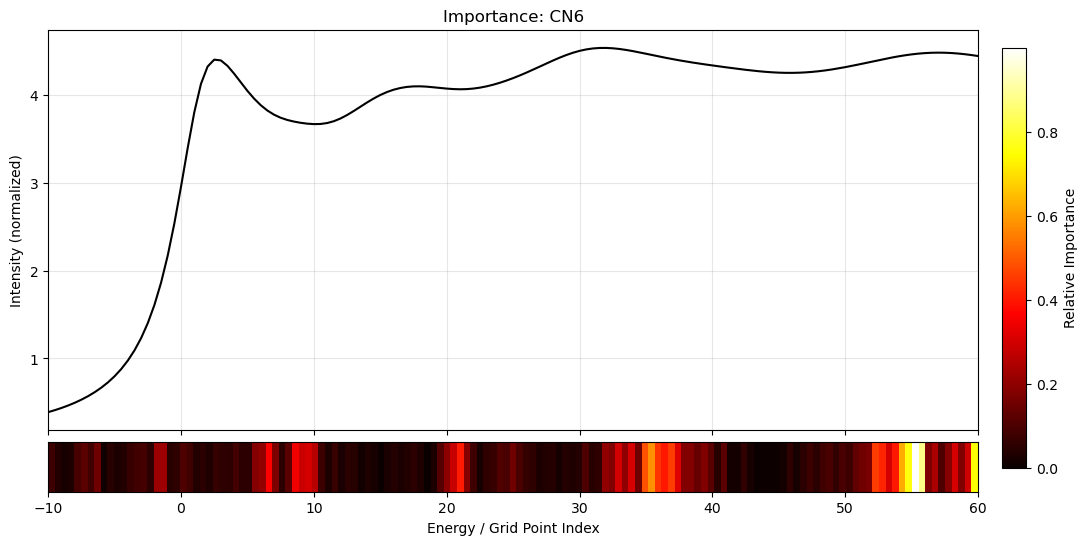

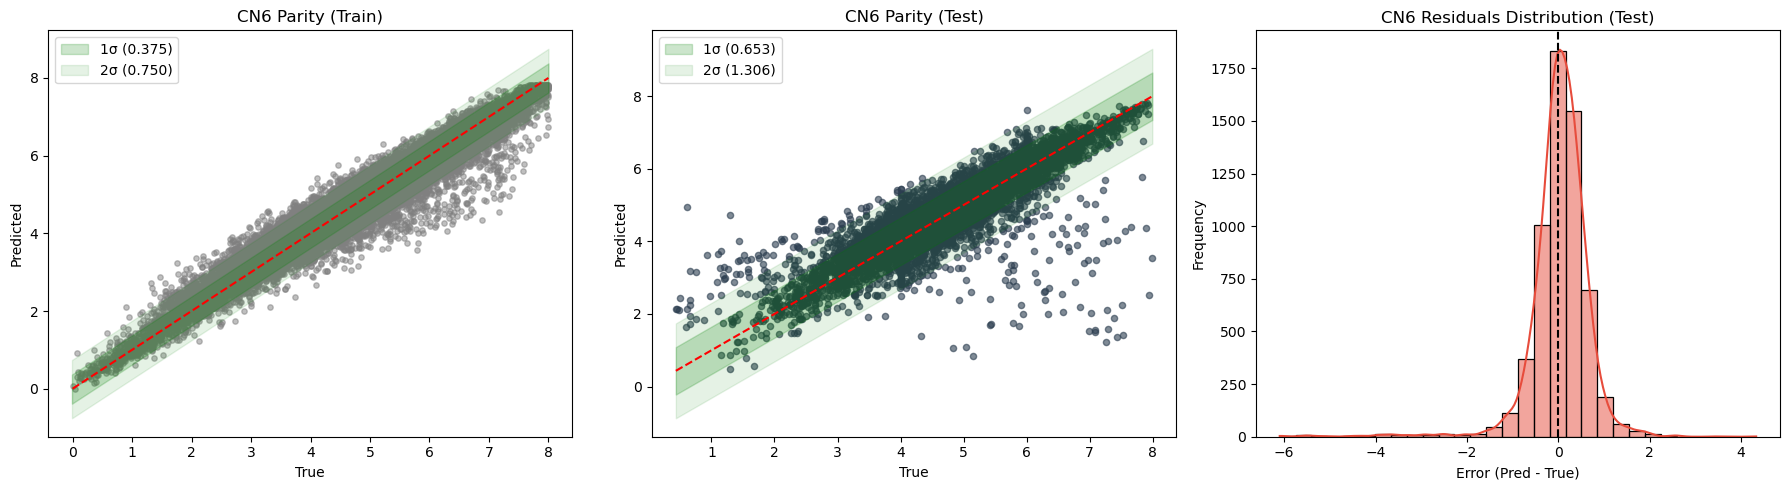


🚀 Моделирование CN7...


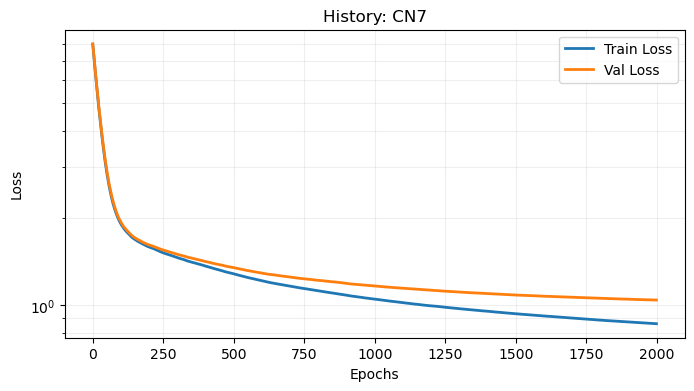

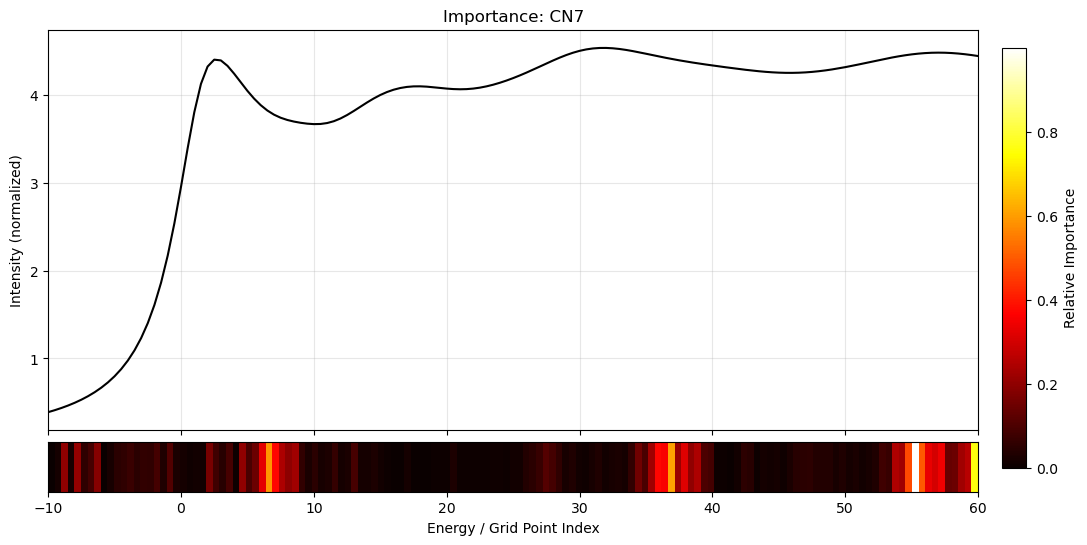

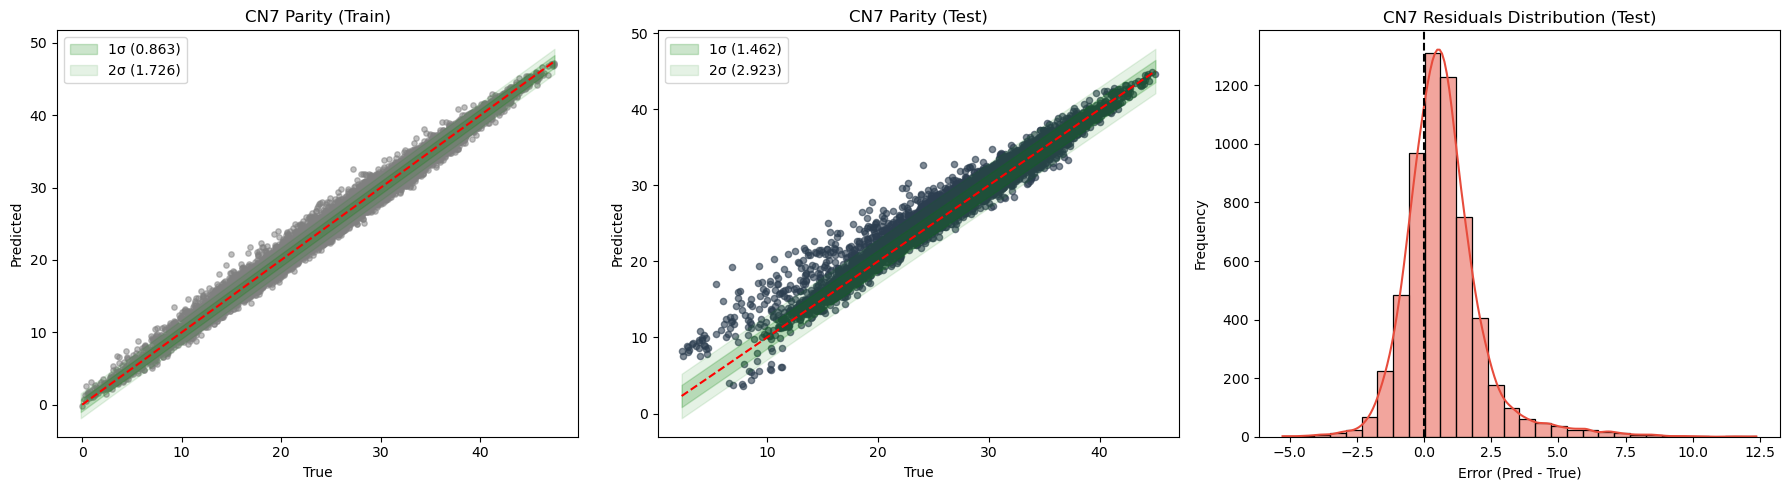


📊 ИТОГОВЫЙ ОТЧЕТ
           R2                  MAE              
Split    test  train    val   test  train    val
Target                                          
CN1    0.9988 0.9995 0.9993 0.0475 0.0348 0.0406
CN2    0.9271 0.9923 0.9887 0.1700 0.0747 0.0890
CN3    0.9170 0.9968 0.9954 0.4918 0.1875 0.2202
CN4    0.9827 0.9953 0.9929 0.1700 0.1147 0.1348
CN5    0.9552 0.9857 0.9792 0.5262 0.3880 0.4504
CN6    0.7048 0.9354 0.9009 0.4206 0.2787 0.3290
CN7    0.9463 0.9889 0.9840 1.1269 0.6633 0.7822
CPU times: total: 1h 45min 55s
Wall time: 7min 27s


In [6]:
%%time

save_root = Path('../processed_data/Results/NotJanisLike/CatBoost/')  
loader = XANESDataLoader(standardize=STAND)
viz = XANESVisualizer()
cbr = CatBoostWrapper(params=catboost_params)
pipeline_cbr = XANESPipeline(loader=loader, visualizer=viz, wrapper_instance=cbr, e_grid=E_GRID)
pipeline_cbr.run(paths=paths_NotJanisLike, save_root=save_root)

###  Сценарий 2А No_Strict (Возможна утечка данных)


🚀 Моделирование CN1...


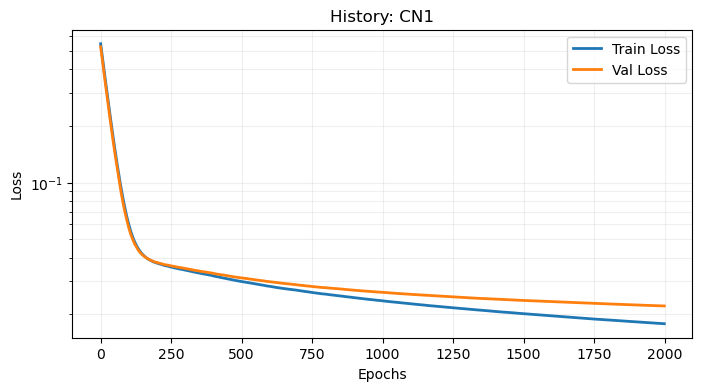

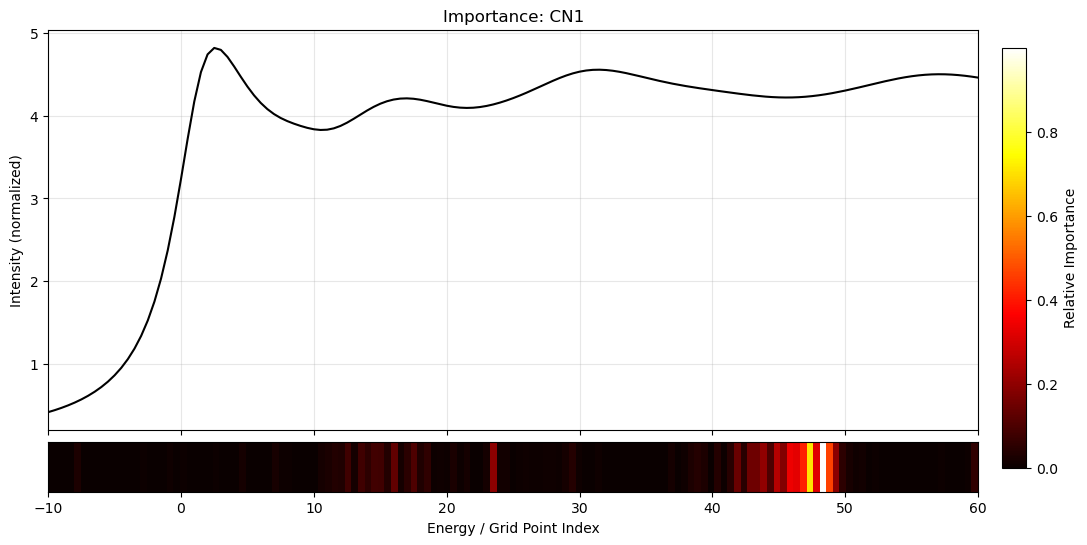

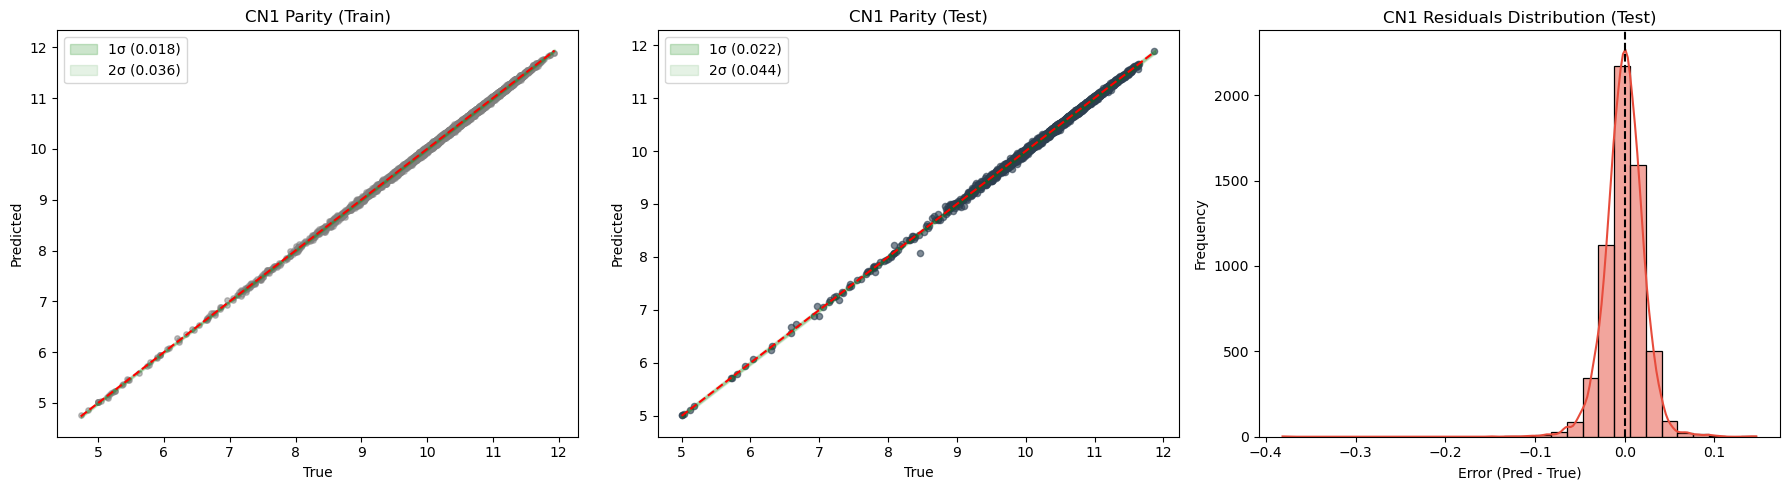


🚀 Моделирование CN2...


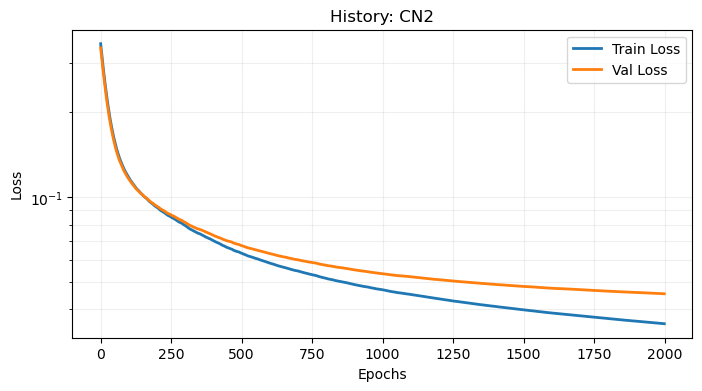

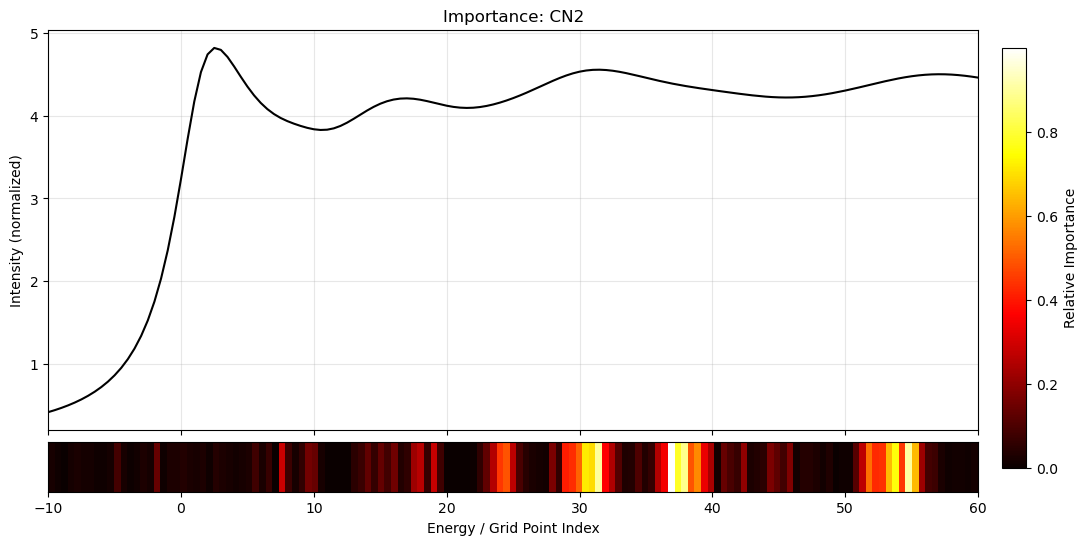

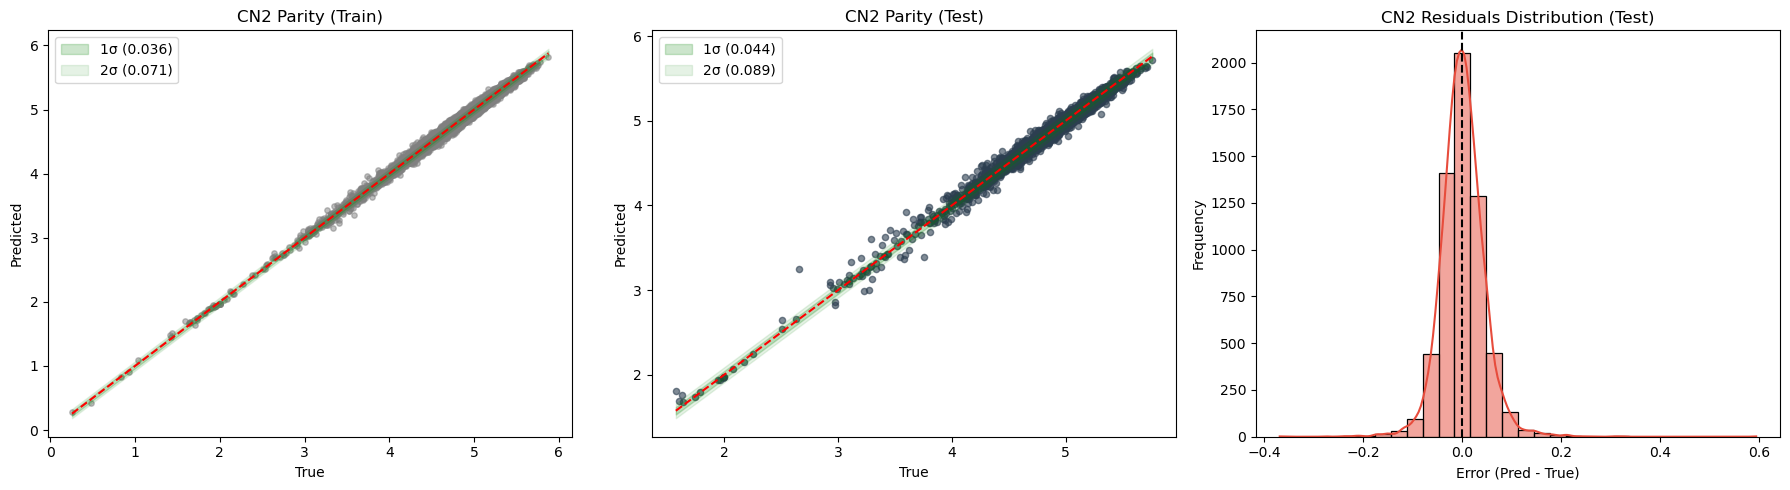


🚀 Моделирование CN3...


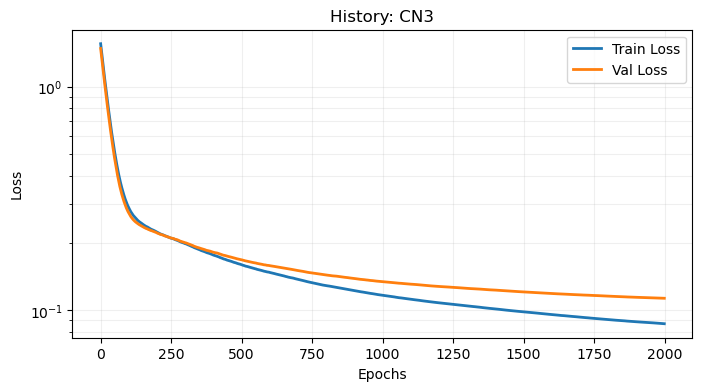

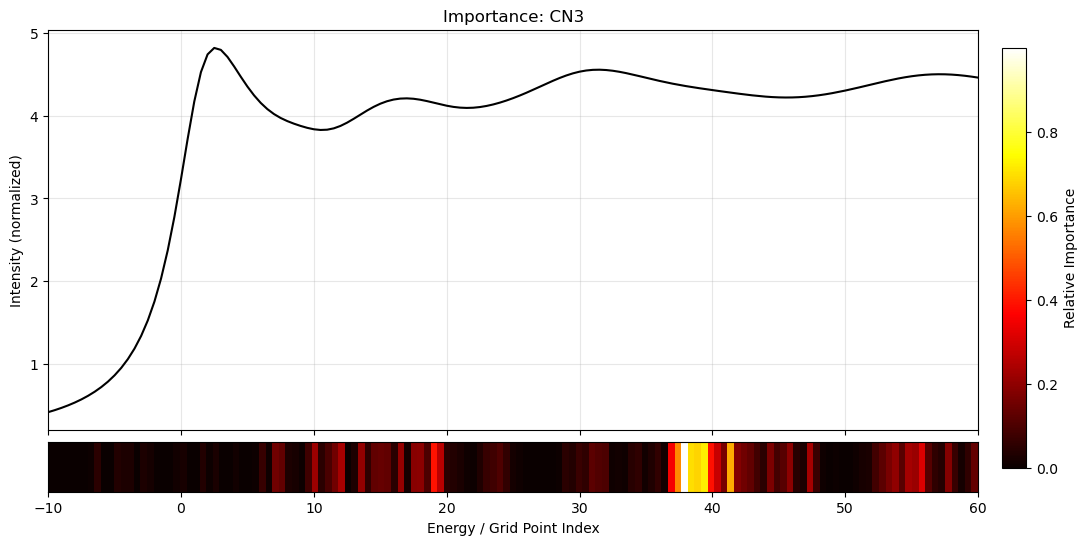

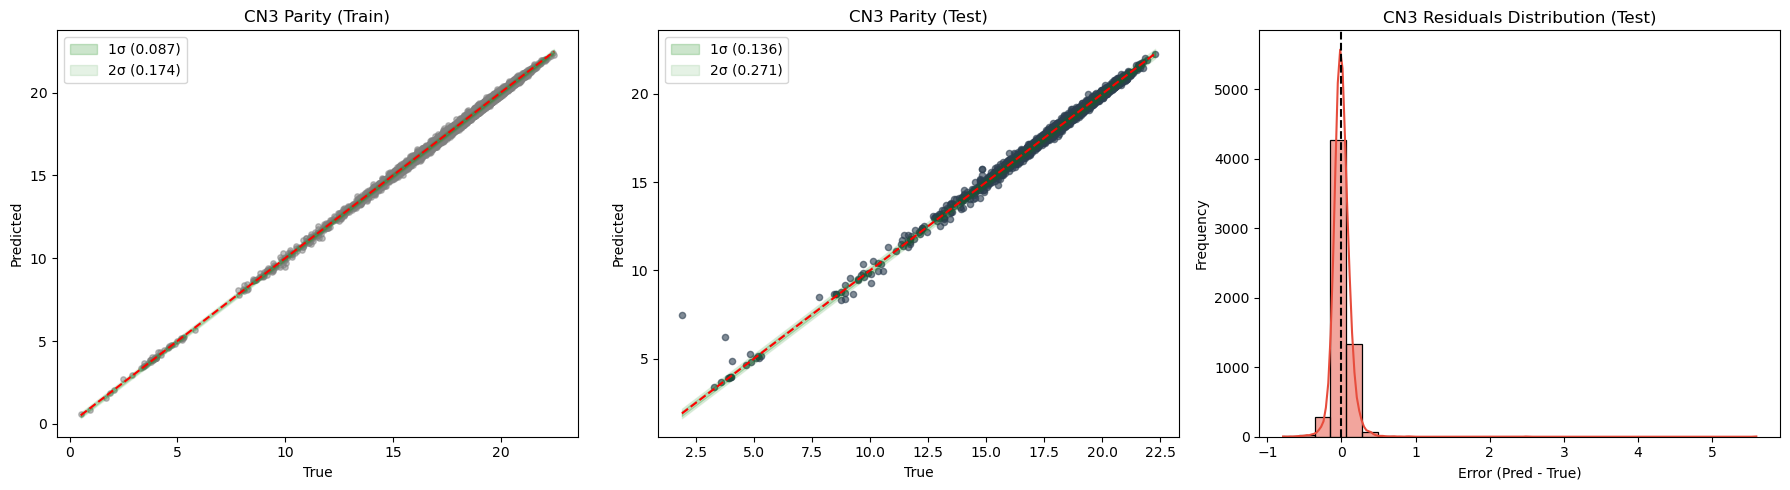


🚀 Моделирование CN4...


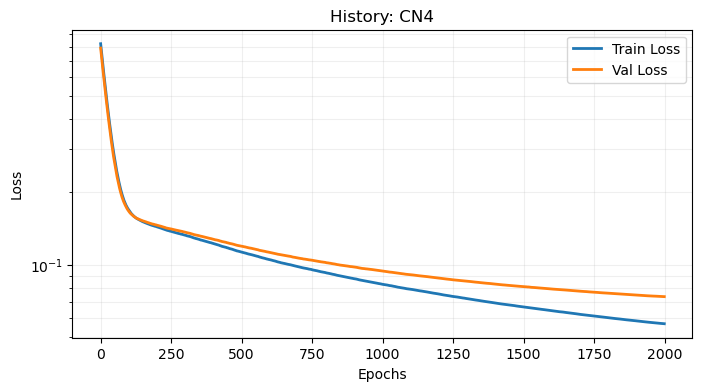

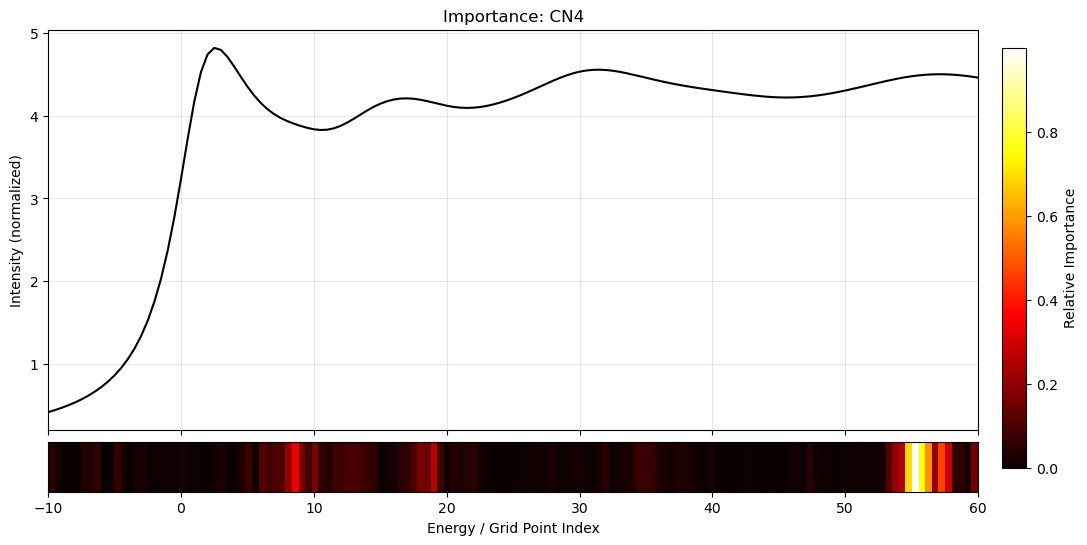

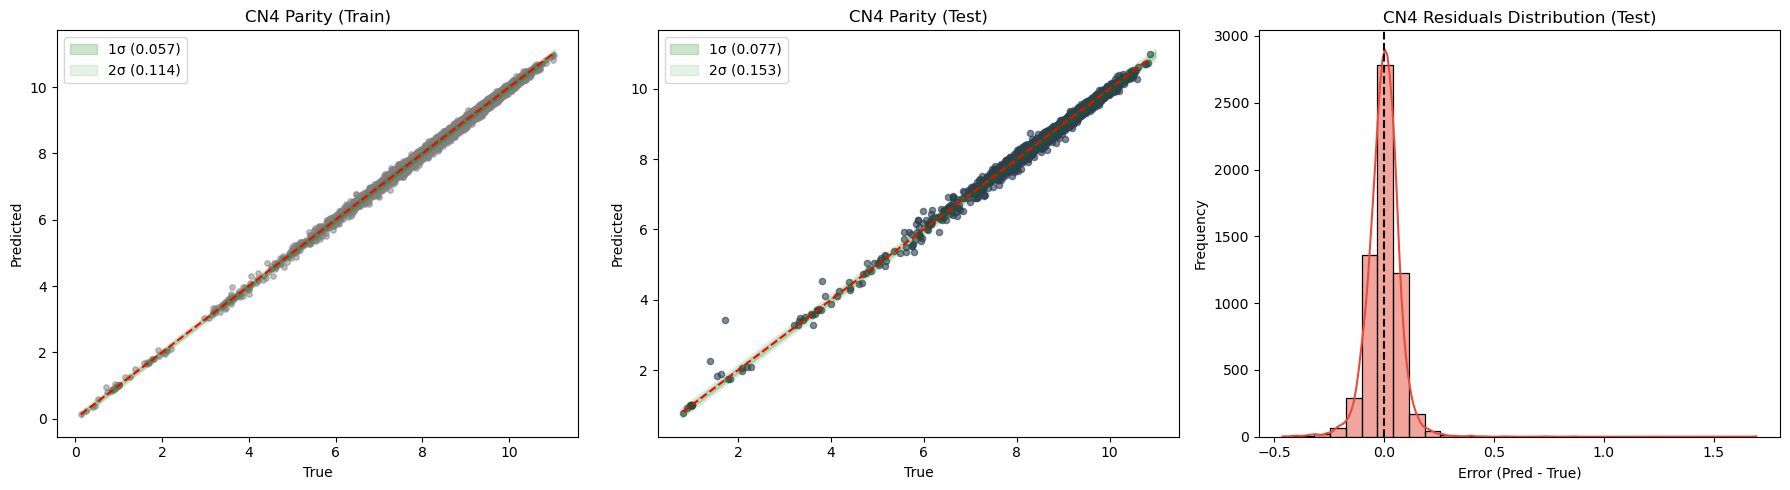


🚀 Моделирование CN5...


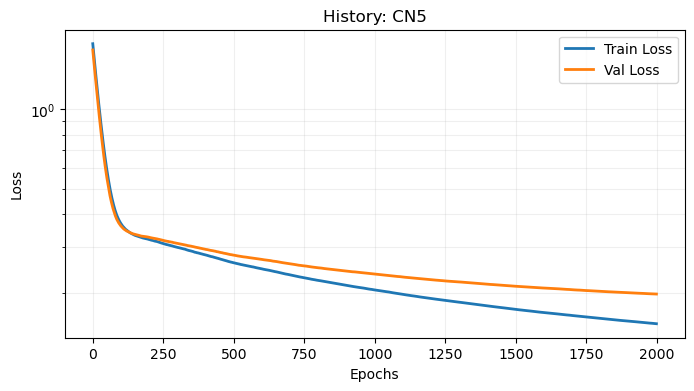

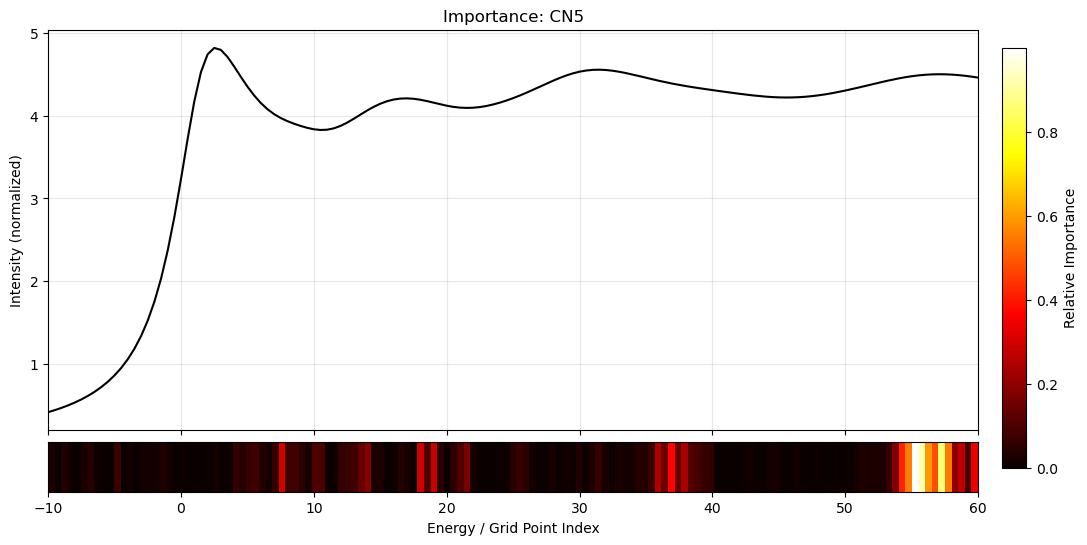

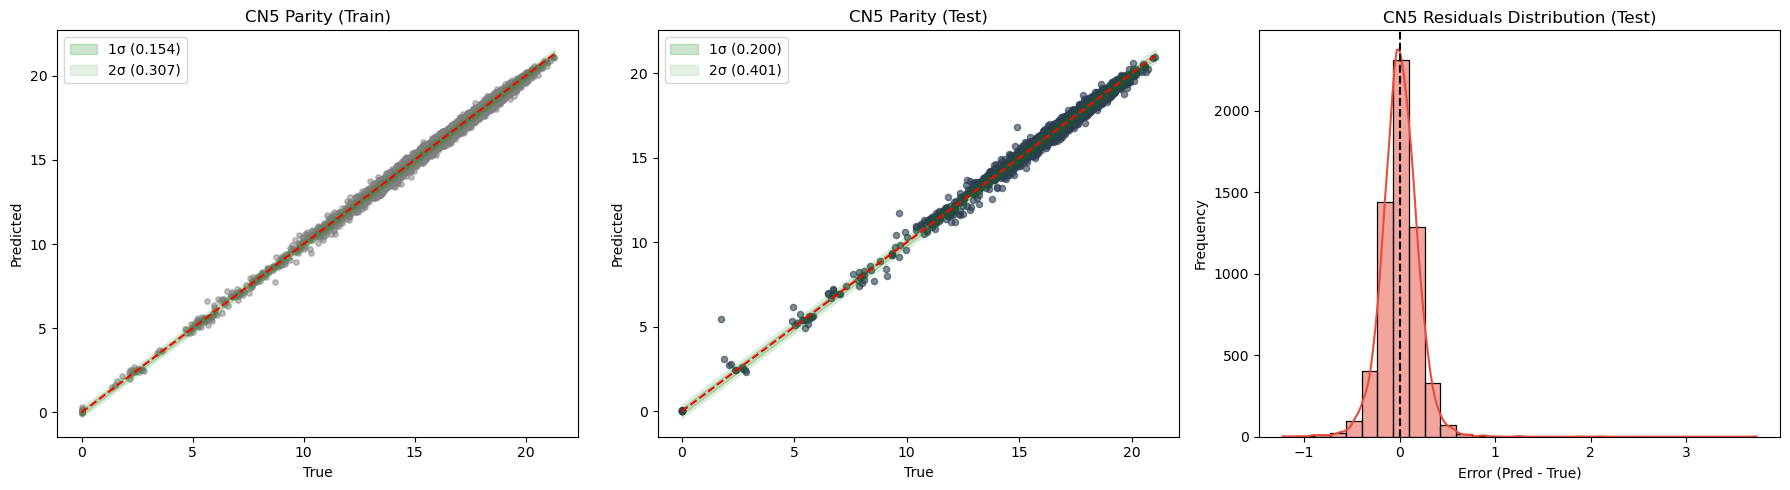


🚀 Моделирование CN6...


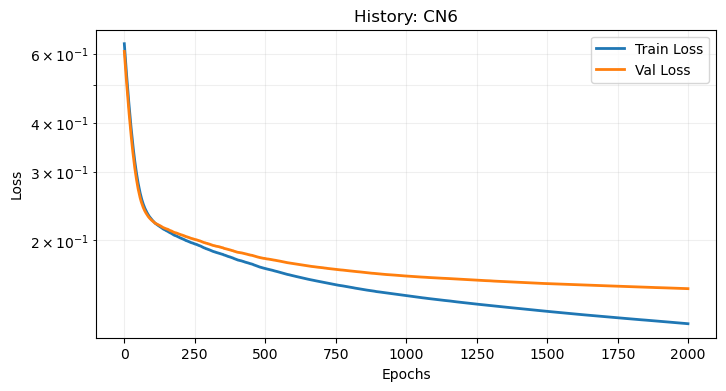

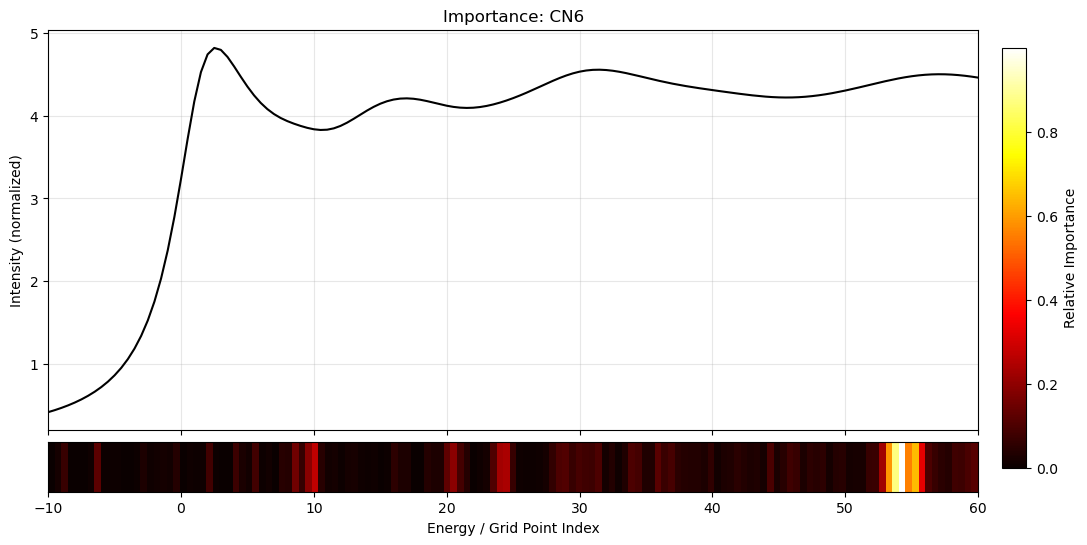

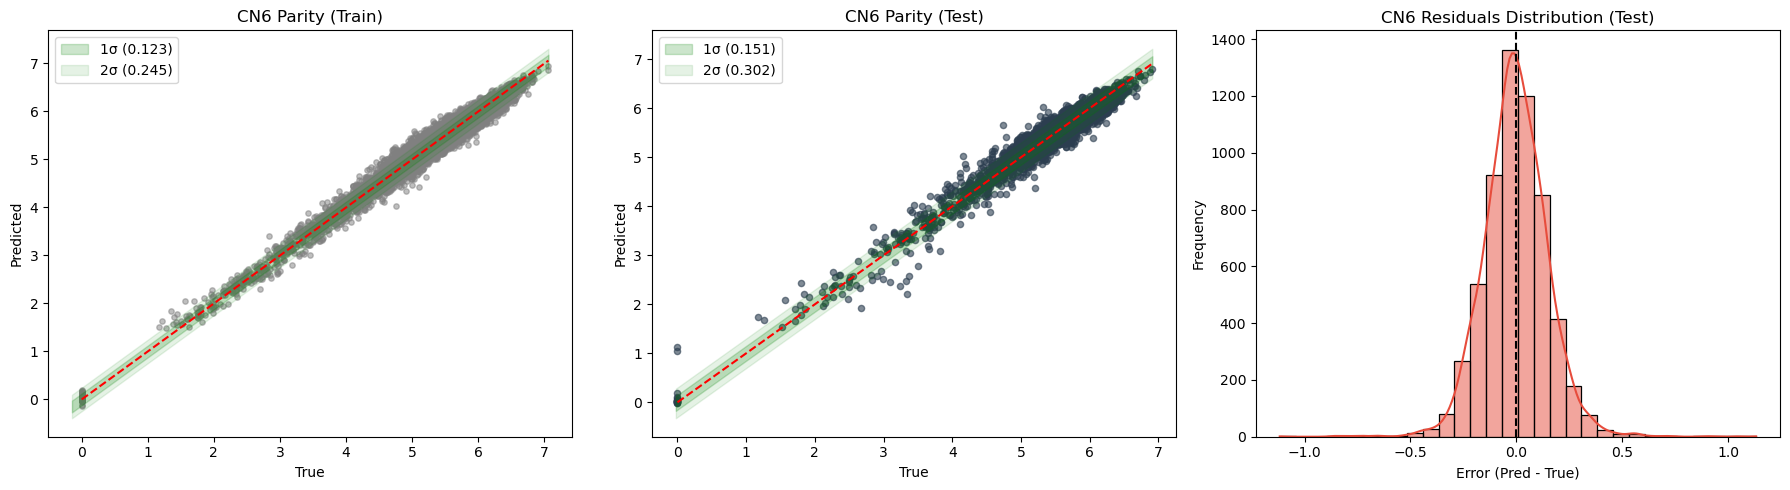


🚀 Моделирование CN7...


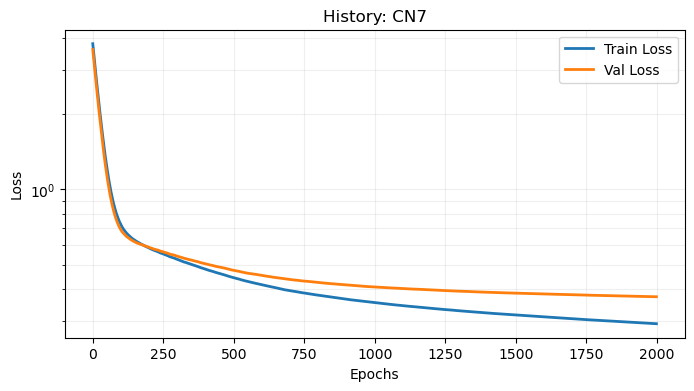

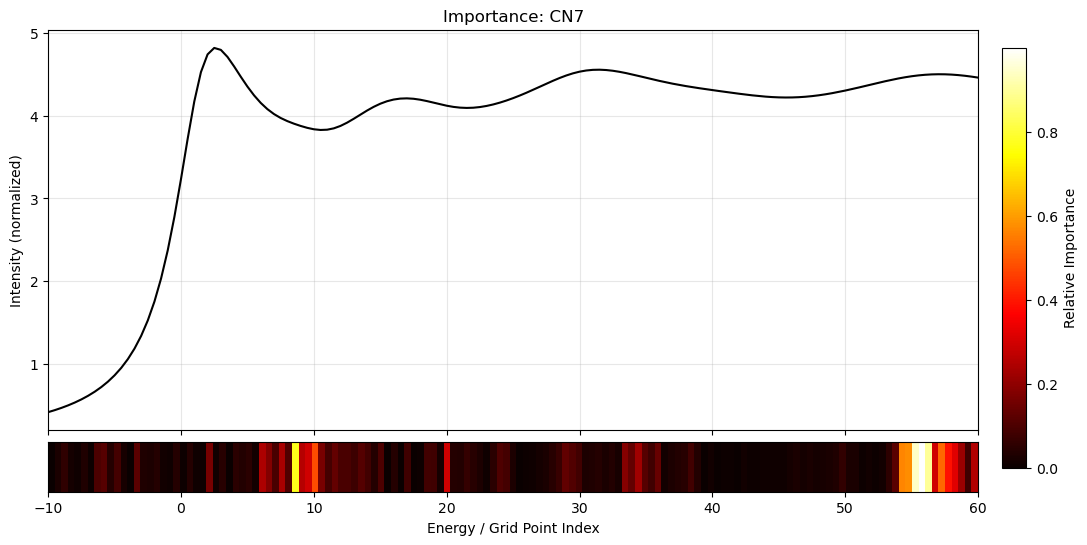

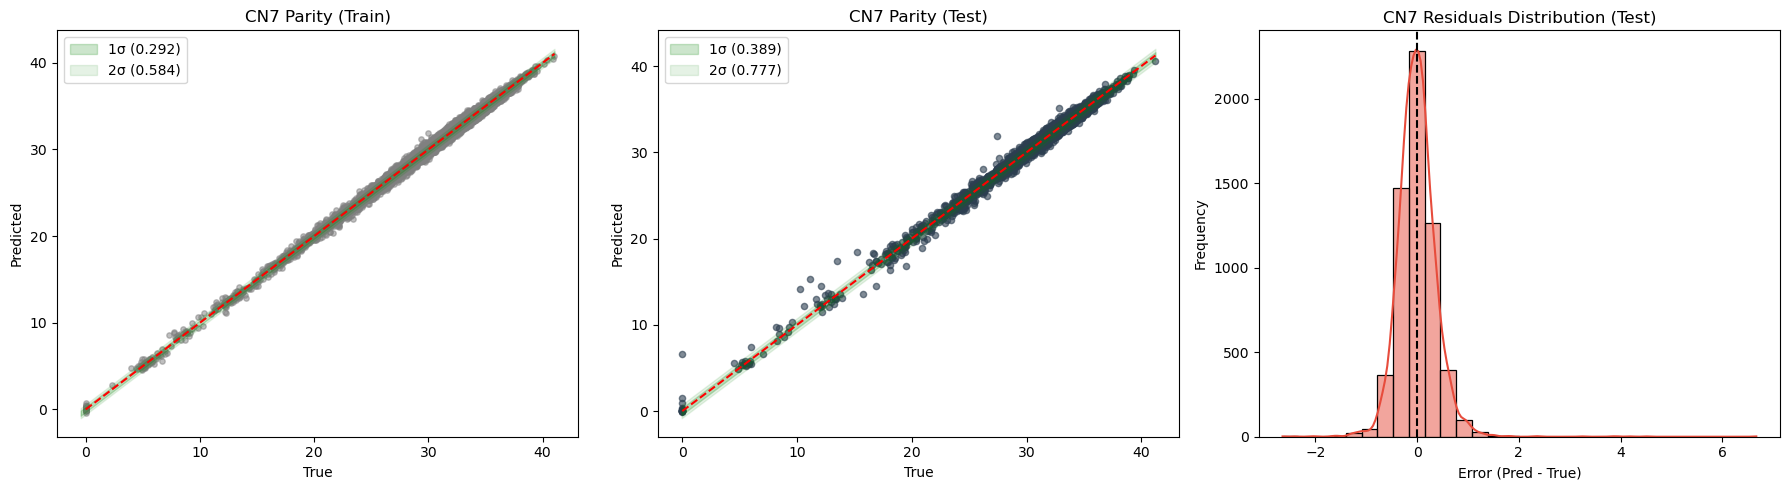


📊 ИТОГОВЫЙ ОТЧЕТ
           R2                  MAE              
Split    test  train    val   test  train    val
Target                                          
CN1    0.9984 0.9990 0.9983 0.0161 0.0138 0.0161
CN2    0.9840 0.9901 0.9828 0.0321 0.0275 0.0330
CN3    0.9928 0.9970 0.9945 0.0808 0.0669 0.0801
CN4    0.9917 0.9955 0.9917 0.0526 0.0433 0.0524
CN5    0.9877 0.9928 0.9866 0.1441 0.1197 0.1470
CN6    0.9461 0.9646 0.9415 0.1138 0.0961 0.1141
CN7    0.9901 0.9944 0.9898 0.2756 0.2280 0.2734
CPU times: total: 1h 39min 43s
Wall time: 6min 59s


In [7]:
%%time

save_root = Path('../processed_data/Results/No_Strict_2A/CatBoost/')  
loader = XANESDataLoader(standardize=STAND)
viz = XANESVisualizer()
cbr = CatBoostWrapper(params=catboost_params)
pipeline_cbr = XANESPipeline(loader=loader, visualizer=viz, wrapper_instance=cbr, e_grid=E_GRID)
pipeline_cbr.run(paths=paths_No_Strict, save_root=save_root)

### Сценарий 2B Lauvian


🚀 Моделирование CN1...


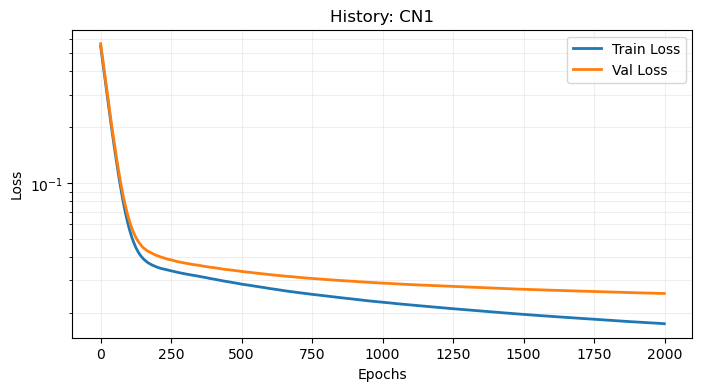

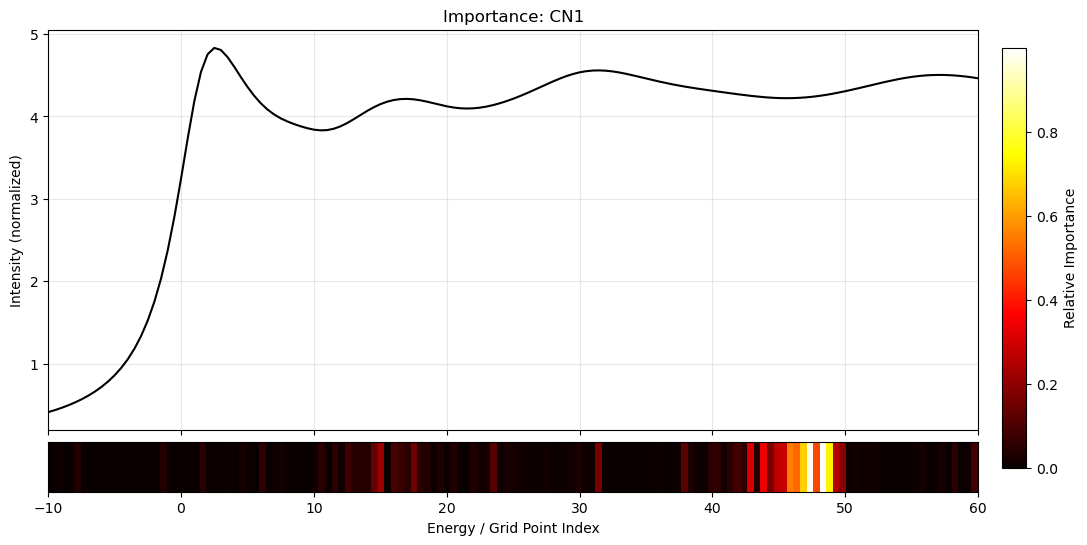

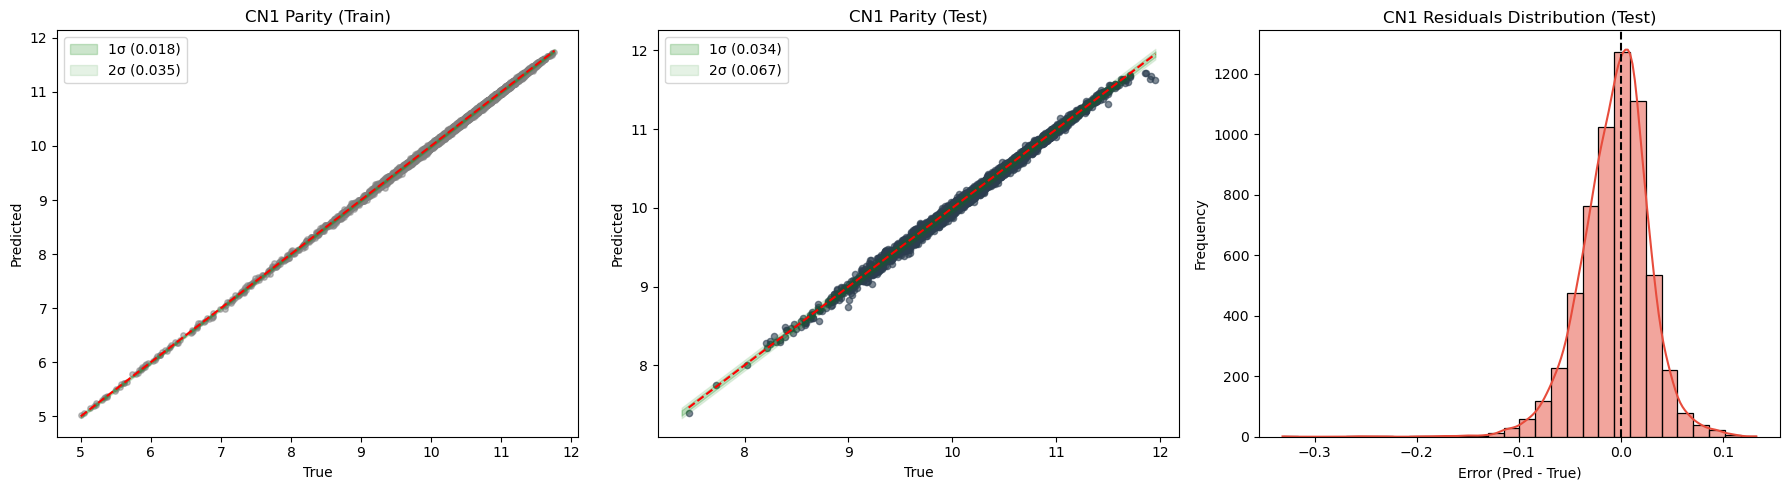


🚀 Моделирование CN2...


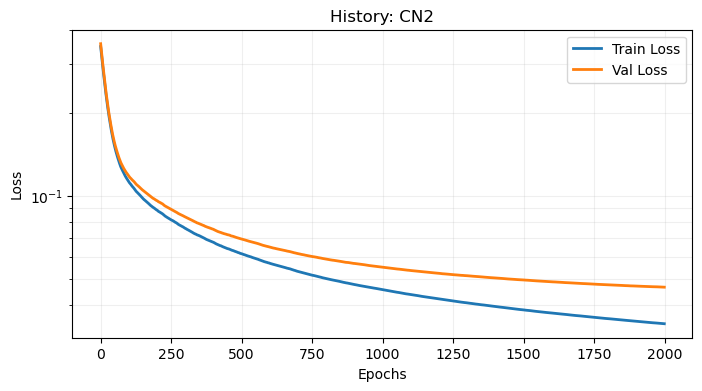

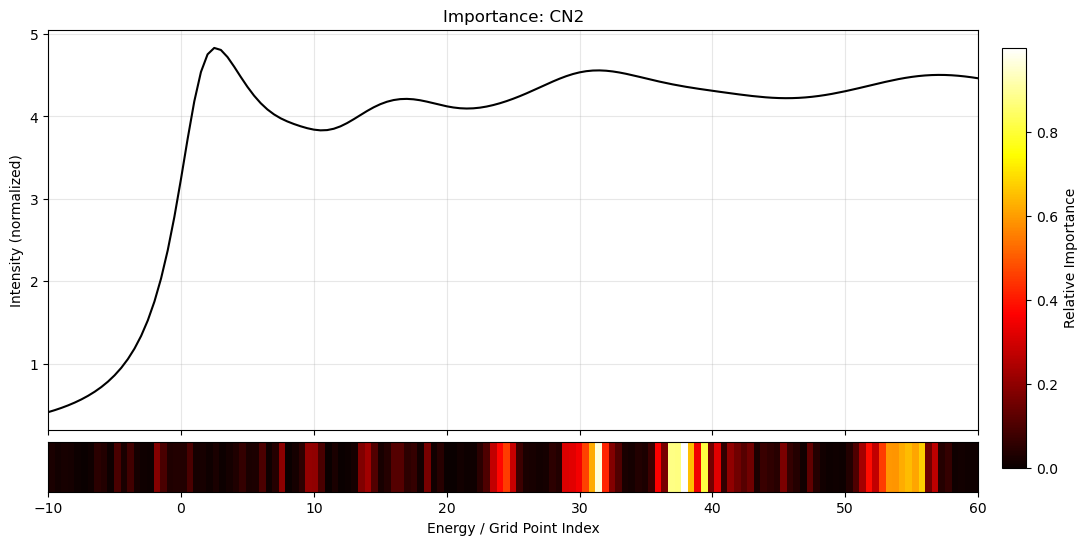

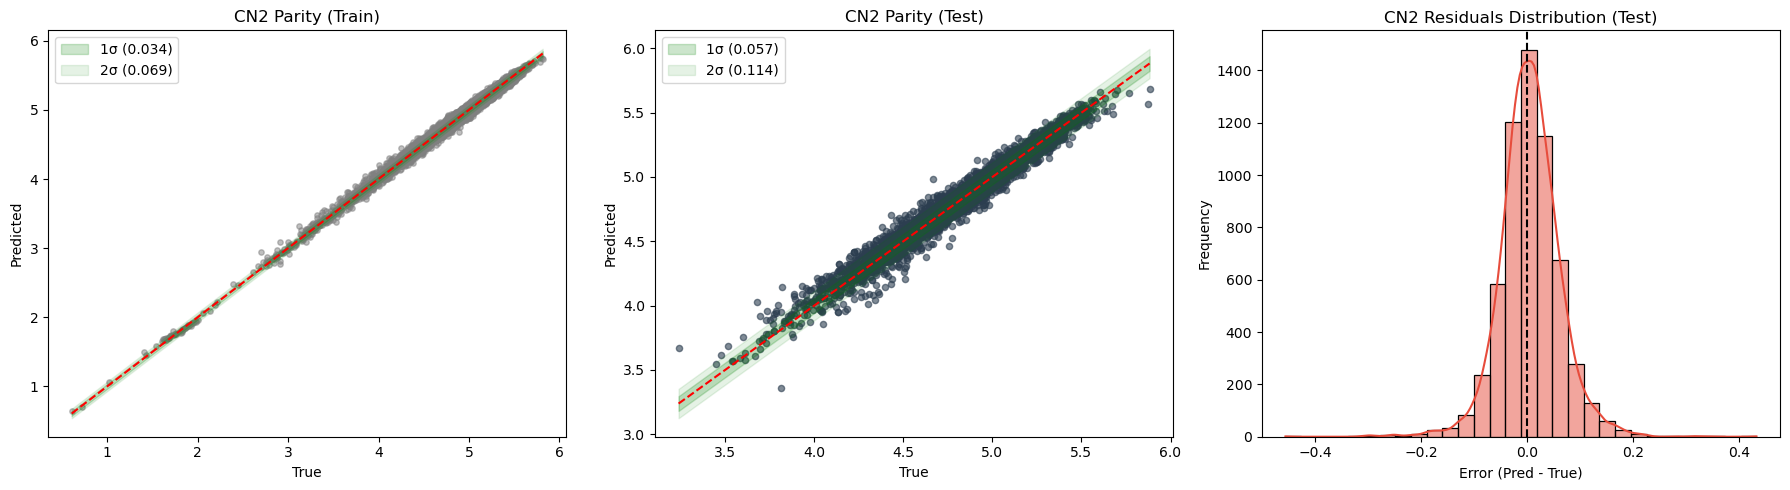


🚀 Моделирование CN3...


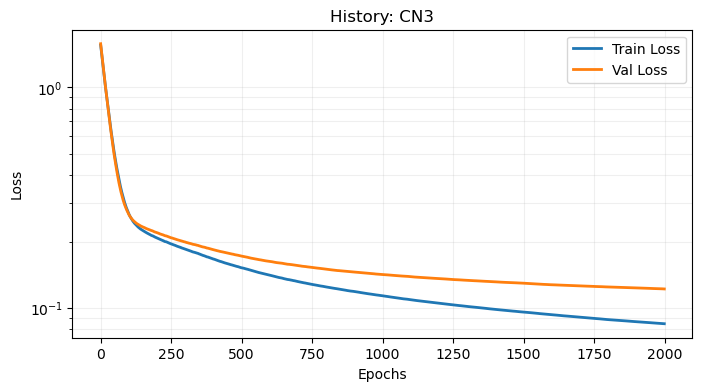

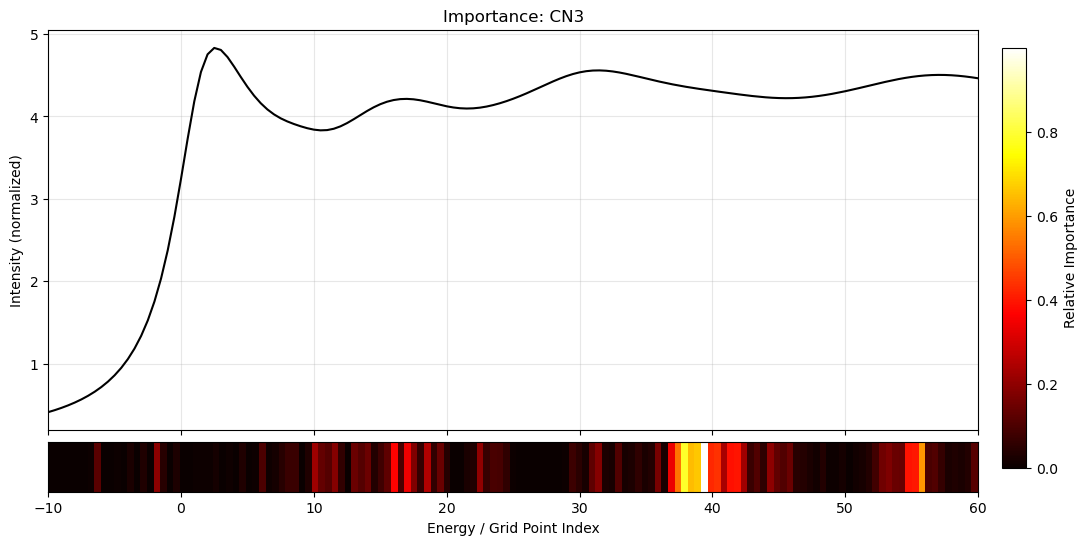

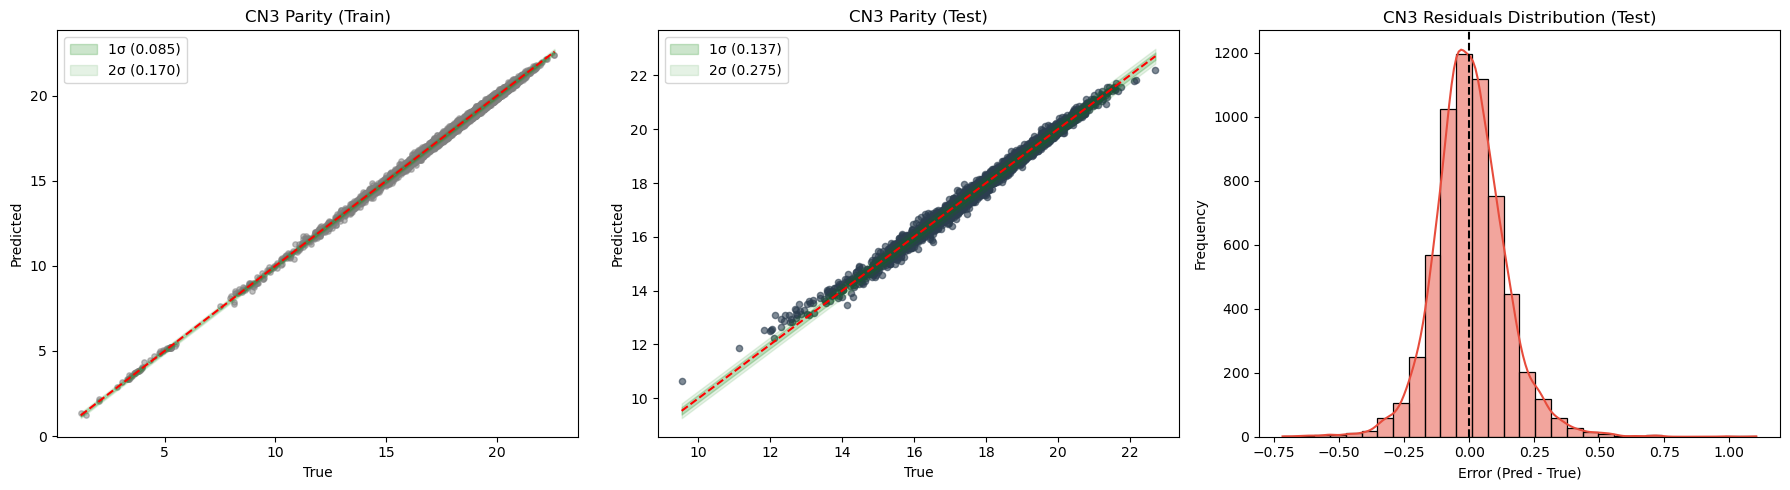


🚀 Моделирование CN4...


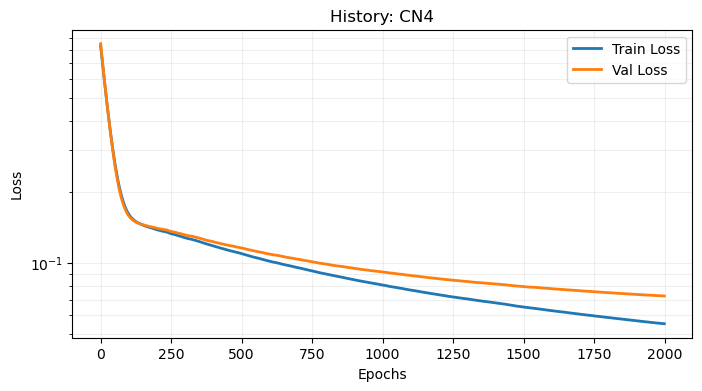

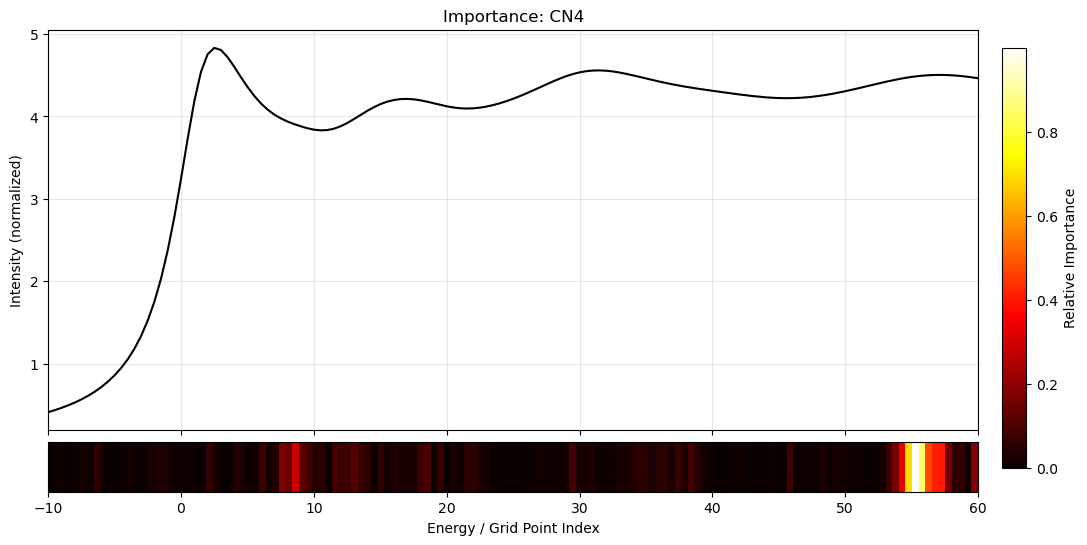

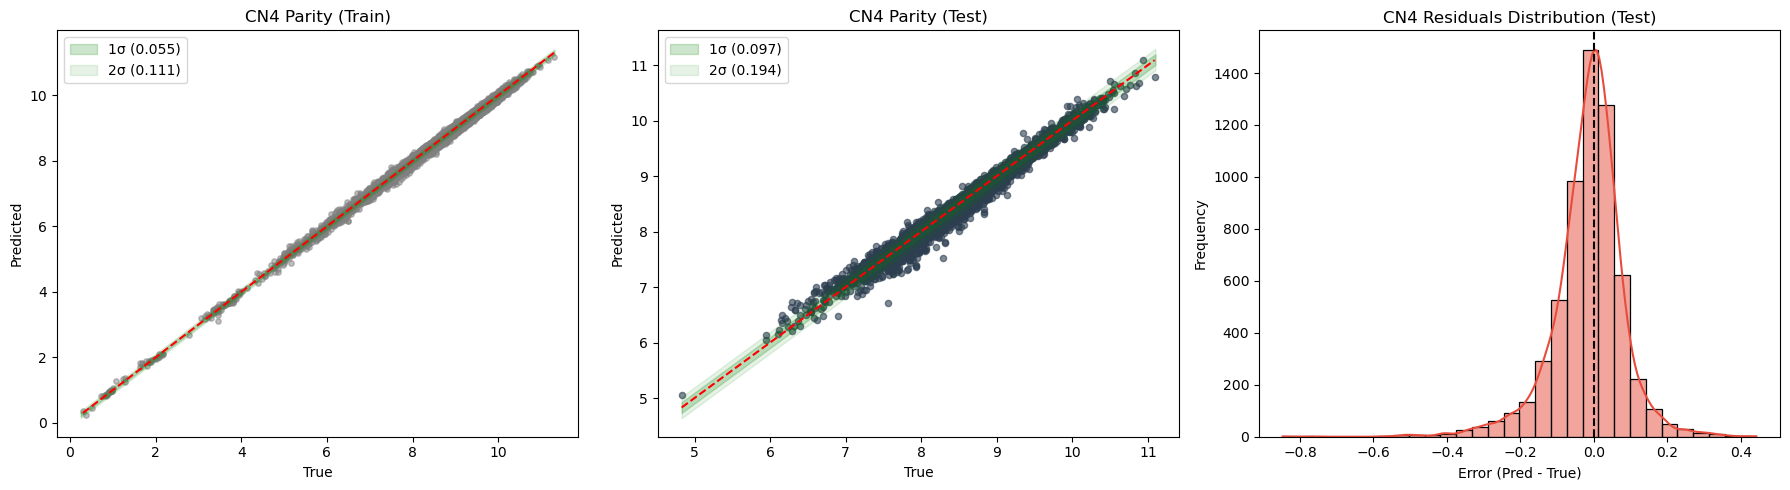


🚀 Моделирование CN5...


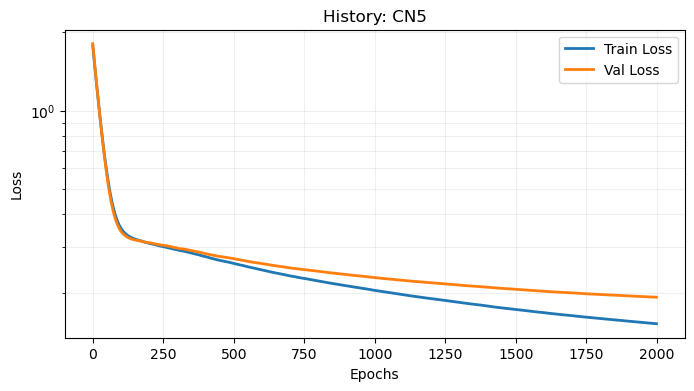

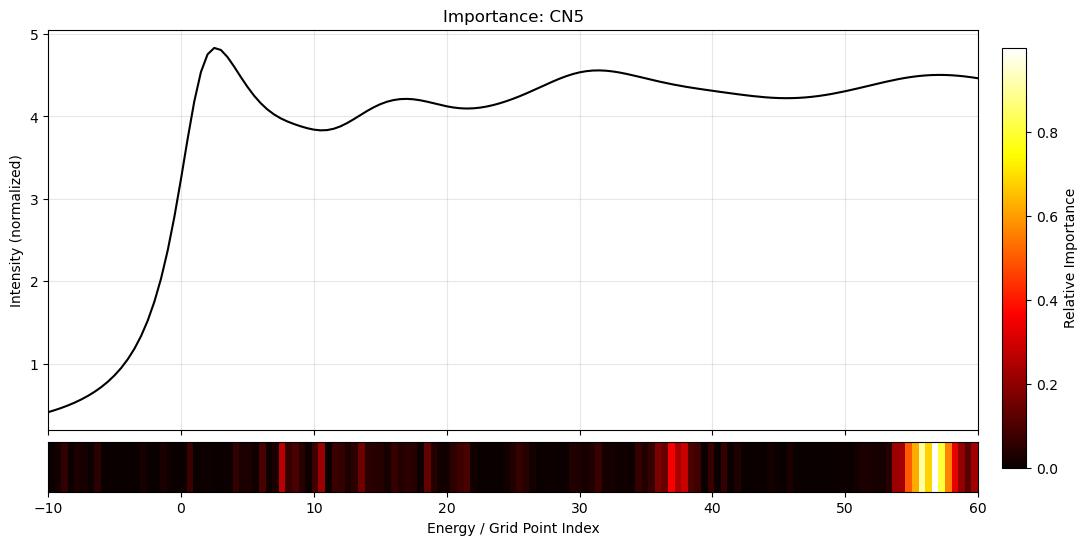

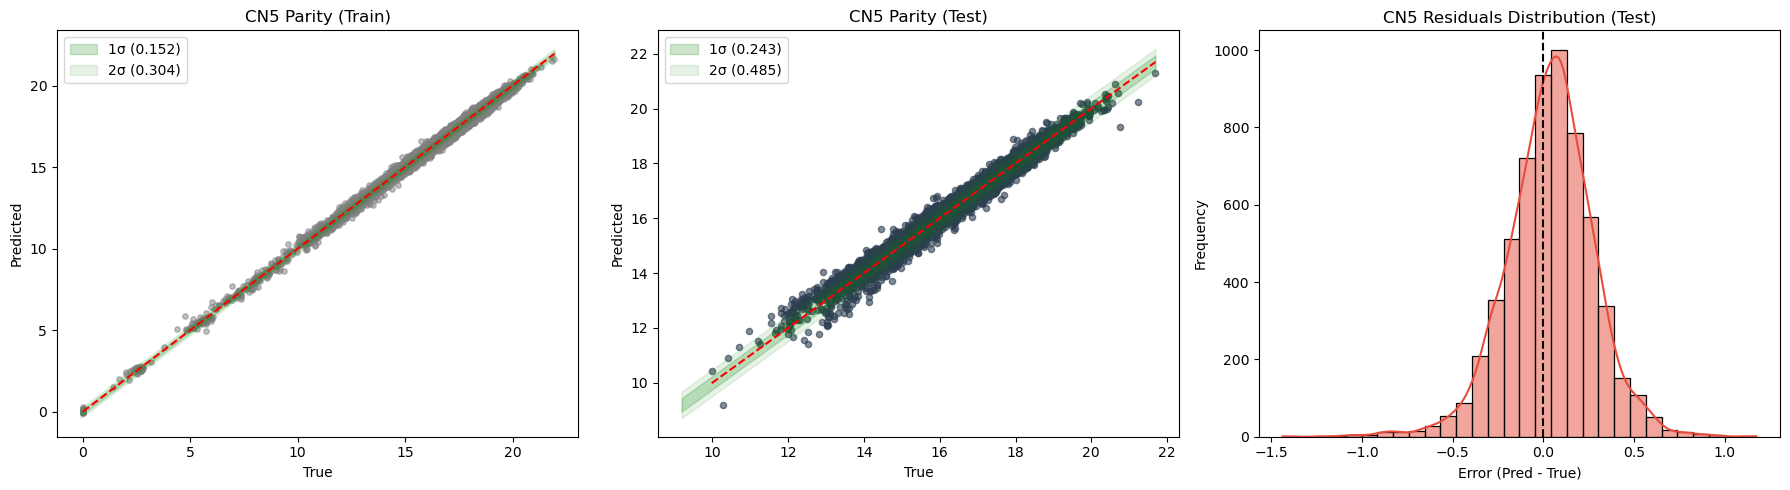


🚀 Моделирование CN6...


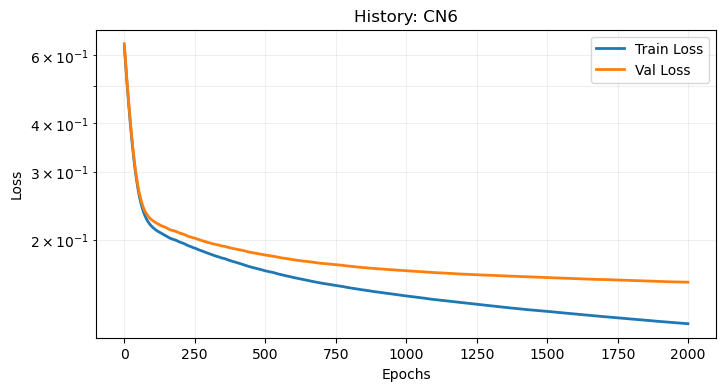

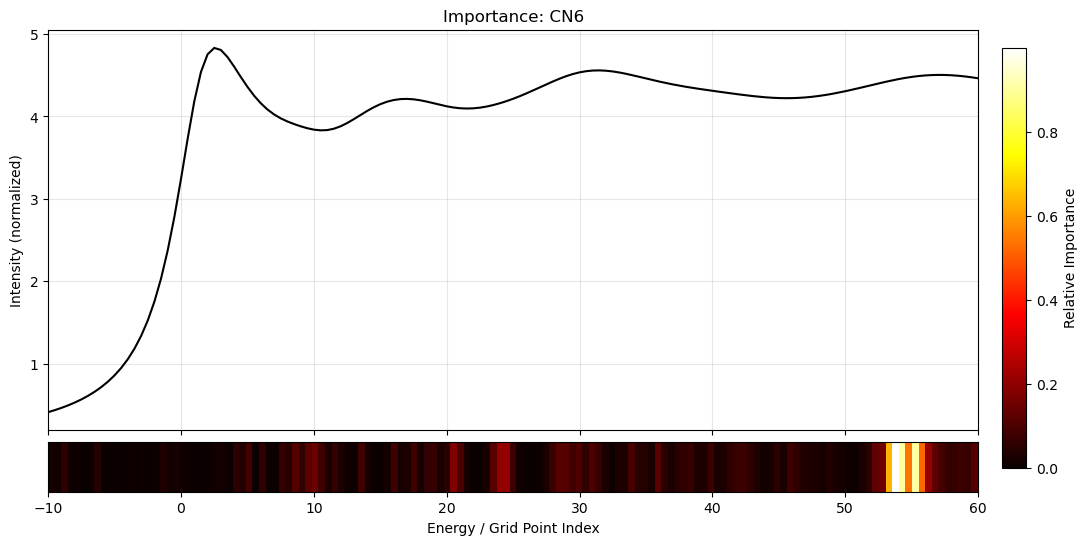

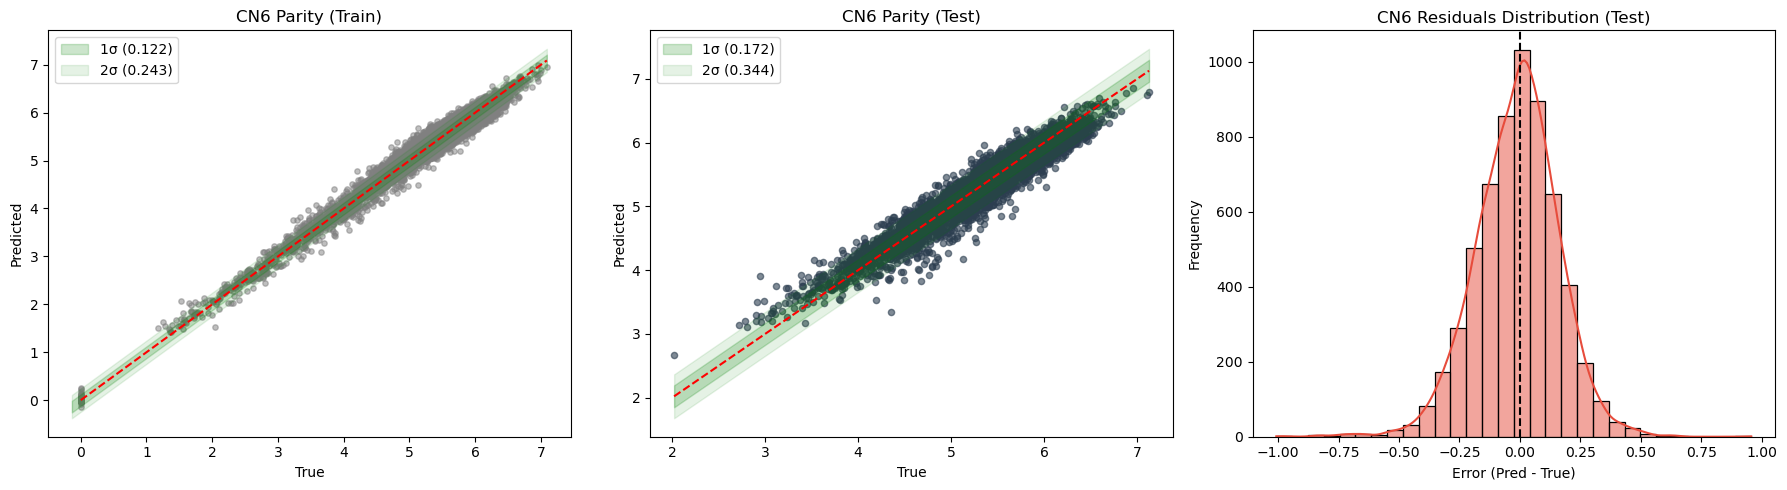


🚀 Моделирование CN7...


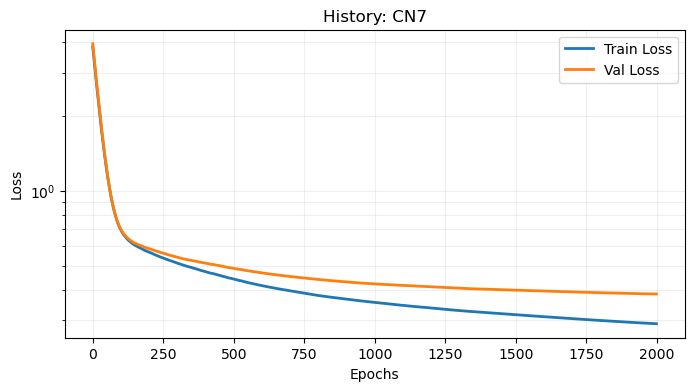

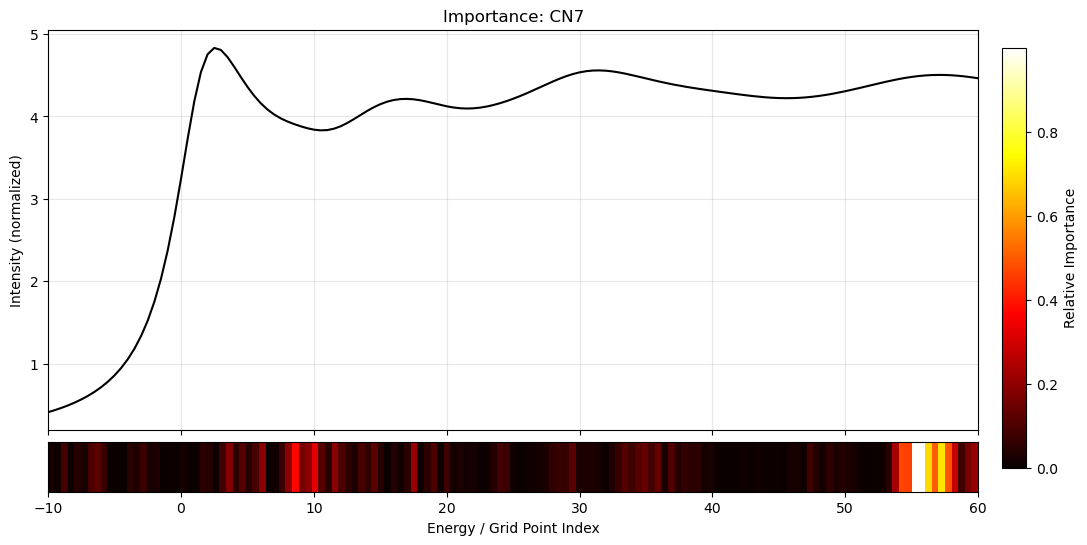

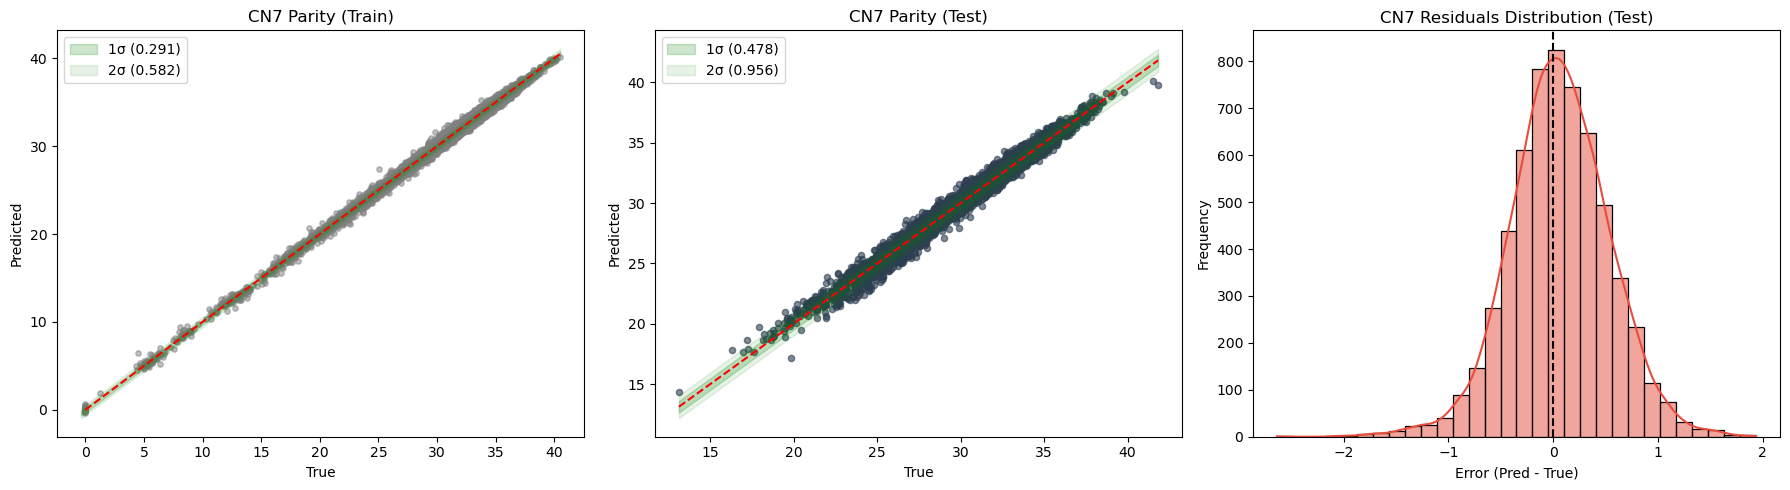


📊 ИТОГОВЫЙ ОТЧЕТ
           R2                  MAE              
Split    test  train    val   test  train    val
Target                                          
CN1    0.9956 0.9990 0.9981 0.0254 0.0136 0.0161
CN2    0.9692 0.9907 0.9837 0.0423 0.0265 0.0314
CN3    0.9905 0.9972 0.9943 0.1026 0.0653 0.0778
CN4    0.9809 0.9958 0.9931 0.0678 0.0423 0.0510
CN5    0.9742 0.9930 0.9893 0.1880 0.1179 0.1387
CN6    0.9254 0.9649 0.9442 0.1326 0.0959 0.1099
CN7    0.9801 0.9945 0.9910 0.3735 0.2275 0.2655
CPU times: total: 1h 44min 18s
Wall time: 7min 41s


In [8]:
%%time

save_root = Path('../processed_data/Results/Lauvian_2B/CatBoost/')  
loader = XANESDataLoader(standardize=STAND)
viz = XANESVisualizer()
cbr = CatBoostWrapper(params=catboost_params)
pipeline_cbr = XANESPipeline(loader=loader, visualizer=viz, wrapper_instance=cbr, e_grid=E_GRID)
pipeline_cbr.run(paths=paths_Lauvian, save_root=save_root)